In [1]:
%pip install osmnx geopandas

Defaulting to user installation because normal site-packages is not writeable
  Using cached osmnx-2.1.1-py3-none-any.whl.metadata (4.7 kB)
  Using cached geopandas-1.2.0-py3-none-any.whl.metadata (2.0 kB)
  Using cached shapely-2.2.0-cp313-cp313-win_amd64.whl.metadata (6.8 kB)
  Using cached pyogrio-0.13.0-cp311-abi3-win_amd64.whl.metadata (6.0 kB)
  Using cached pyproj-3.8.0-cp313-cp313-win_amd64.whl.metadata (40 kB)
Using cached osmnx-2.1.1-py3-none-any.whl (104 kB)
Using cached geopandas-1.2.0-py3-none-any.whl (368 kB)
   ---------------------------------------- 0.0/23.8 MB ? eta -:--:--
   ---------------------------------------- 0.3/23.8 MB ? eta -:--:--
    --------------------------------------- 0.5/23.8 MB 2.1 MB/s eta 0:00:12
   -- ------------------------------------- 1.3/23.8 MB 2.5 MB/s eta 0:00:10
   -- ------------------------------------- 1.6/23.8 MB 2.1 MB/s eta 0:00:11
   --- ------------------------------------ 1.8/23.8 MB 2.1 MB/s eta 0:00:11
   --- ----------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [2]:
import datetime 
import json
import os
import random

In [3]:
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd

In [4]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [5]:
PLACES = [
    "Şehzadeler, Manisa, Turkey",
    "Yunusemre, Manisa, Turkey",
]
OUT = "data"
os.makedirs(OUT, exist_ok=True)
 
ox.settings.use_cache = True
ox.settings.log_console = True

In [6]:
print("Sürüş ağı indiriliyor...")
G = ox.graph_from_place(PLACES, network_type="drive", simplify=True)

Sürüş ağı indiriliyor...


In [7]:
G = ox.truncate.largest_component(G, strongly=True)

In [8]:
Gm = ox.convert.to_undirected(G)
H = nx.Graph()
for u, v, d in Gm.edges(data=True):
    L = d.get("length", 0.0)
    if H.has_edge(u, v):
        if L < H[u][v]["length"]:
            H[u][v].update(length=L, highway=str(d.get("highway")), name=str(d.get("name", "")))
    else:
        H.add_edge(u, v, length=L, highway=str(d.get("highway")), name=str(d.get("name", "")))
for n, d in Gm.nodes(data=True):
    H.add_node(n, x=d["x"], y=d["y"])
H.remove_edges_from(nx.selfloop_edges(H))

In [9]:
edges = pd.DataFrame(
    [(u, v, d["length"], d["highway"], d["name"]) for u, v, d in H.edges(data=True)],
    columns=["source", "target", "length_m", "highway", "name"],
)
edges.to_csv(f"{OUT}/manisa_edges.csv", index=False, encoding="utf-8")
 
nodes = pd.DataFrame(
    [(n, d["x"], d["y"], H.degree(n)) for n, d in H.nodes(data=True)],
    columns=["node_id", "lon", "lat", "degree"],
)
nodes.to_csv(f"{OUT}/manisa_nodes.csv", index=False, encoding="utf-8")
 
nx.write_graphml(H, f"{OUT}/manisa.graphml")

In [10]:
print("Ticari noktalar (POI) indiriliyor...")
tags = {
    "shop": True,
    "amenity": ["cafe", "restaurant", "fast_food", "bank", "pharmacy", "marketplace"],
}
poi = ox.features_from_place(PLACES, tags=tags)
poi = poi.reset_index()
cent = poi.geometry.to_crs(3857).centroid.to_crs(4326)
poi["lon"], poi["lat"] = cent.x, cent.y
keep = [c for c in ["element", "id", "shop", "amenity", "lon", "lat"] if c in poi.columns]
poi[keep].to_csv(f"{OUT}/manisa_poi.csv", index=False, encoding="utf-8")

Ticari noktalar (POI) indiriliyor...


ResponseStatusCodeError: 'overpass-api.de' responded: 502 Bad Gateway # 502 Gateway Timeout

This Overpass API server is currently at capacity. All query workers are busy
and the request queue is full.

## What to do

Retry your request using exponential backoff: wait a short interval, then retry.
If the request fails again, double the wait time and retry again.

## For heavy or automated use

This public endpoint is intended for browser-based and human-operated tools.
For automated or high-volume use, run a local Overpass API instance:

https://github.com/b1tw153/Overpass-API/blob/main/README.md


In [1]:
import pandas as pd, networkx as nx, json, datetime, os

OUT = "data"
edges = pd.read_csv(f"{OUT}/manisa_edges.csv")
H = nx.from_pandas_edgelist(edges, "source", "target", ["length_m"])

n, m = H.number_of_nodes(), H.number_of_edges()
comps = list(nx.connected_components(H))
stats = {
    "toplama_tarihi": "2026-10-25",
    "kaynak": "OpenStreetMap (ODbL) - OSMnx",
    "bolgeler": ["Şehzadeler, Manisa", "Yunusemre, Manisa"],
    "dugum_sayisi": n,
    "kenar_sayisi": m,
    "yogunluk": nx.density(H),
    "bilesen_sayisi": len(comps),
    "en_buyuk_bilesen_dugum": max(len(c) for c in comps),
    "ortalama_derece": 2 * m / n,
    "toplam_yol_uzunlugu_km": float(edges["length_m"].sum() / 1000),
    "seed": 42,
}
with open(f"{OUT}/temel_istatistikler.json", "w", encoding="utf-8") as f:
    json.dump(stats, f, ensure_ascii=False, indent=2)
print(json.dumps(stats, ensure_ascii=False, indent=2))

{
  "toplama_tarihi": "2026-10-25",
  "kaynak": "OpenStreetMap (ODbL) - OSMnx",
  "bolgeler": [
    "Şehzadeler, Manisa",
    "Yunusemre, Manisa"
  ],
  "dugum_sayisi": 11152,
  "kenar_sayisi": 16429,
  "yogunluk": 0.0002642253906753092,
  "bilesen_sayisi": 1,
  "en_buyuk_bilesen_dugum": 11152,
  "ortalama_derece": 2.946377331420373,
  "toplam_yol_uzunlugu_km": 2209.8199990328276,
  "seed": 42
}


In [1]:
import networkx as nx
import pandas as pd
import numpy as np

# Veriyi tekrar yükle
edges = pd.read_csv("data/manisa_edges.csv")

H = nx.from_pandas_edgelist(
    edges,
    source="source",
    target="target",
    edge_attr="length_m"
)

print("Düğüm sayısı:", H.number_of_nodes())
print("Kenar sayısı:", H.number_of_edges())

# Yoğunluk
density = nx.density(H)

# Ortalama derece
avg_degree = sum(dict(H.degree()).values()) / H.number_of_nodes()

# Kümelenme katsayısı
avg_clustering = nx.average_clustering(H)

# Derece benzeşimi (assortativity)
assortativity = nx.degree_assortativity_coefficient(H)

print("\n--- TEMEL AĞ ÖLÇÜLERİ ---")
print("Yoğunluk:", density)
print("Ortalama derece:", avg_degree)
print("Ortalama kümelenme katsayısı:", avg_clustering)
print("Derece assortativity:", assortativity)

Düğüm sayısı: 11152
Kenar sayısı: 16429

--- TEMEL AĞ ÖLÇÜLERİ ---
Yoğunluk: 0.0002642253906753092
Ortalama derece: 2.946377331420373
Ortalama kümelenme katsayısı: 0.04646401243424199
Derece assortativity: 0.10946861262527188


In [2]:
import random
import numpy as np
import networkx as nx

SEED = 42
random.seed(SEED)

# Örnekleme yapılacak düğüm sayısı
sample_size = 250

sample_nodes = random.sample(
    list(H.nodes()),
    sample_size
)

distances = []

print("Örneklemeli en kısa yol hesabı başladı...")

for i, source in enumerate(sample_nodes):

    # Yol uzunluğuna göre en kısa yollar
    lengths = nx.single_source_dijkstra_path_length(
        H,
        source,
        weight="length_m"
    )

    # Sadece örneklenen diğer düğümlere olan mesafeleri al
    for target in sample_nodes:
        if target != source and target in lengths:
            distances.append(lengths[target])

    if (i + 1) % 50 == 0:
        print(f"{i + 1}/{sample_size} düğüm tamamlandı")

# Aynı çiftler iki kez hesaplandığı için sonuç değişmez;
# ortalama ve maksimum değer yine kullanılabilir.

avg_shortest_path_m = np.mean(distances)
approx_diameter_m = np.max(distances)

print("\n--- ÖRNEKLEMELİ YOL ÖLÇÜLERİ ---")

print(
    "Ortalama en kısa yol:",
    round(avg_shortest_path_m / 1000, 2),
    "km"
)

print(
    "Yaklaşık çap:",
    round(approx_diameter_m / 1000, 2),
    "km"
)

print("Örneklenen düğüm sayısı:", sample_size)
print("Seed:", SEED)


Örneklemeli en kısa yol hesabı başladı...
50/250 düğüm tamamlandı
100/250 düğüm tamamlandı
150/250 düğüm tamamlandı
200/250 düğüm tamamlandı
250/250 düğüm tamamlandı

--- ÖRNEKLEMELİ YOL ÖLÇÜLERİ ---
Ortalama en kısa yol: 17.68 km
Yaklaşık çap: 65.83 km
Örneklenen düğüm sayısı: 250
Seed: 42


In [3]:
# Her düğümün derecesini al
degrees = [d for n, d in H.degree()]

print("Düğüm sayısı:", len(degrees))
print("En düşük derece:", min(degrees))
print("En yüksek derece:", max(degrees))
print("Ortalama derece:", sum(degrees) / len(degrees))

Düğüm sayısı: 11152
En düşük derece: 1
En yüksek derece: 6
Ortalama derece: 2.946377331420373


Derece dağılımı:
Degree 1: 1207 düğüm (P(k)=0.1082)
Degree 2: 180 düğüm (P(k)=0.0161)
Degree 3: 7822 düğüm (P(k)=0.7014)
Degree 4: 1891 düğüm (P(k)=0.1696)
Degree 5: 51 düğüm (P(k)=0.0046)
Degree 6: 1 düğüm (P(k)=0.0001)


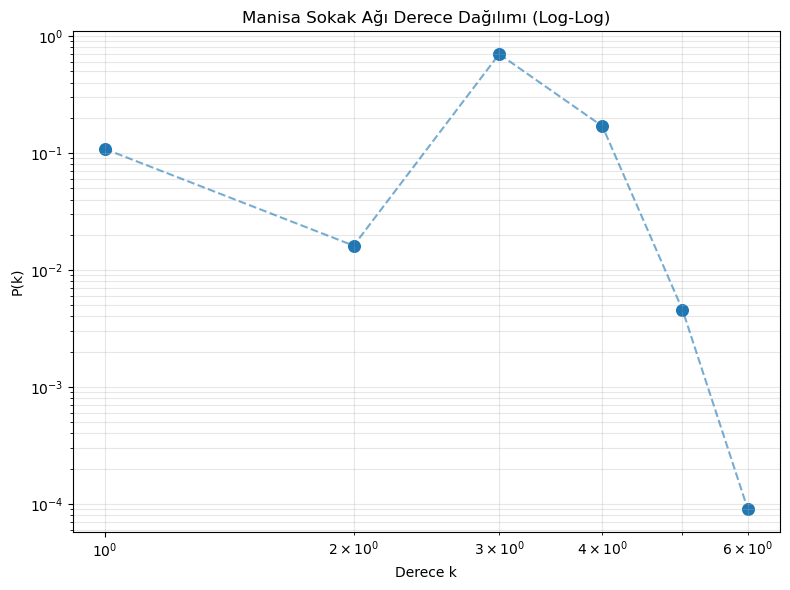

In [4]:
import matplotlib.pyplot as plt
from collections import Counter

# Derecelerin kaç kez görüldüğünü hesapla
degree_counts = Counter(degrees)

# Dereceleri küçükten büyüğe sırala
k = sorted(degree_counts.keys())

# Her derecenin görülme olasılığı P(k)
pk = [
    degree_counts[d] / len(degrees)
    for d in k
]

print("Derece dağılımı:")
for degree, probability in zip(k, pk):
    print(
        f"Degree {degree}: "
        f"{degree_counts[degree]} düğüm "
        f"(P(k)={probability:.4f})"
    )

# Log-log grafik
plt.figure(figsize=(8, 6))

plt.scatter(k, pk, s=70)
plt.plot(k, pk, linestyle="--", alpha=0.6)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Derece k")
plt.ylabel("P(k)")
plt.title("Manisa Sokak Ağı Derece Dağılımı (Log-Log)")

plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "data/derece_dagilimi_loglog.png",
    dpi=300
)

plt.show()

In [5]:
%pip install powerlaw

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [6]:
import powerlaw
import numpy as np

degree_data = np.array(degrees)

fit = powerlaw.Fit(
    degree_data,
    discrete=True,
    verbose=False
)

print("--- POWER LAW SONUÇLARI ---")
print("Alpha:", fit.power_law.alpha)
print("xmin:", fit.power_law.xmin)
print("KS mesafesi:", fit.power_law.D)

--- POWER LAW SONUÇLARI ---
Alpha: 2.466357421874999
xmin: 2.0
KS mesafesi: 0.49181913994024323


C:\Users\PC\AppData\Roaming\Python\Python313\site-packages\powerlaw\distributions.py:743: OptimizeWarning: Initial guess is not within the specified bounds
  result = scipy.optimize.minimize(fit_function,


In [7]:
# Power law ile lognormal karşılaştırması
R_log, p_log = fit.distribution_compare(
    "power_law",
    "lognormal"
)

# Power law ile exponential karşılaştırması
R_exp, p_exp = fit.distribution_compare(
    "power_law",
    "exponential"
)

print("--- DAĞILIM KARŞILAŞTIRMASI ---")

print("\nPower Law vs Lognormal")
print("R =", R_log)
print("p =", p_log)

print("\nPower Law vs Exponential")
print("R =", R_exp)
print("p =", p_exp)

--- DAĞILIM KARŞILAŞTIRMASI ---

Power Law vs Lognormal
R = -11817.256708781955
p = 0.0

Power Law vs Exponential
R = -2901.492131075211
p = 0.0


In [8]:
R_le, p_le = fit.distribution_compare(
    "lognormal",
    "exponential"
)

print("Lognormal vs Exponential")
print("R =", R_le)
print("p =", p_le)


Lognormal vs Exponential
R = 8915.76457770737
p = 0.0


In [9]:
print("Merkeziyet hesaplamaları başlıyor...")

# 1) Degree centrality
degree_centrality = nx.degree_centrality(H)

print("Degree centrality tamamlandı.")

# 2) PageRank
# length_m bir mesafe/maliyet olduğu için PageRank'te doğrudan ağırlık
# olarak kullanmıyoruz.
pagerank = nx.pagerank(H)

print("PageRank tamamlandı.")

Merkeziyet hesaplamaları başlıyor...
Degree centrality tamamlandı.
PageRank tamamlandı.


In [10]:
# 3) Ağırlıklı Betweenness Centrality
# Ağ büyük olduğu için 300 düğüm üzerinden yaklaşık hesaplama

betweenness = nx.betweenness_centrality(
    H,
    k=300,
    normalized=True,
    weight="length_m",
    seed=42
)

print("Yaklaşık ağırlıklı betweenness tamamlandı.")

Yaklaşık ağırlıklı betweenness tamamlandı.


In [11]:
print("Closeness centrality hesaplanıyor...")

closeness = nx.closeness_centrality(
    H,
    distance="length_m"
)

print("Closeness centrality tamamlandı.")


Closeness centrality hesaplanıyor...
Closeness centrality tamamlandı.


In [12]:
centrality_df = pd.DataFrame({
    "node_id": list(H.nodes()),
    "degree": [degree_centrality[n] for n in H.nodes()],
    "betweenness": [betweenness[n] for n in H.nodes()],
    "closeness": [closeness[n] for n in H.nodes()],
    "pagerank": [pagerank[n] for n in H.nodes()]
})

top10 = centrality_df.sort_values(
    "betweenness",
    ascending=False
).head(10)

print("--- BETWENNESS'E GÖRE EN ÖNEMLİ 10 KAVŞAK ---")
display(top10)

--- BETWENNESS'E GÖRE EN ÖNEMLİ 10 KAVŞAK ---


,node_id,degree,betweenness,closeness,pagerank
999,2251603222,0.000269,0.175191,0.000092,0.000087
516,983383019,0.000359,0.173529,0.000089,0.000106
4695,2251420435,0.000269,0.169200,0.000092,0.000082
993,2251463963,0.000269,0.165324,0.000092,0.000088
520,2351998468,0.000359,0.160191,0.000089,0.000107
486,2351998437,0.000269,0.156433,0.000086,0.000086
86,2249636291,0.000359,0.156432,0.000085,0.000110
501,2249731472,0.000269,0.155433,0.000087,0.000090
4681,12997816396,0.000359,0.154445,0.000092,0.000101
2310,1872287837,0.000269,0.152453,0.000088,0.000087


In [13]:
# Merkeziyet ölçüleri arasındaki Spearman korelasyonu

spearman_corr = centrality_df[
    ["degree", "betweenness", "closeness", "pagerank"]
].corr(method="spearman")

print("--- SPEARMAN KORELASYON MATRİSİ ---")
display(spearman_corr)

--- SPEARMAN KORELASYON MATRİSİ ---


,degree,betweenness,closeness,pagerank
degree,1.000000,0.452318,0.236684,0.734087
betweenness,0.452318,1.000000,0.269859,0.278639
closeness,0.236684,0.269859,1.000000,-0.140468
pagerank,0.734087,0.278639,-0.140468,1.000000


In [14]:
centrality_df.to_csv(
    "data/centrality_results.csv",
    index=False,
    encoding="utf-8"
)

top10.to_csv(
    "data/top10_betweenness.csv",
    index=False,
    encoding="utf-8"
)

print("Merkeziyet sonuçları kaydedildi.")

Merkeziyet sonuçları kaydedildi.


In [15]:
from networkx.algorithms.community import louvain_communities
from networkx.algorithms.community.quality import modularity

print("Louvain topluluk analizi başlıyor...")

louvain_runs = []

for seed in range(10):
    communities = louvain_communities(
        H,
        weight=None,
        resolution=1,
        seed=seed
    )

    mod = modularity(
        H,
        communities,
        weight=None
    )

    louvain_runs.append({
        "seed": seed,
        "communities": communities,
        "modularity": mod
    })

    print(
        f"Seed {seed}: "
        f"{len(communities)} topluluk, "
        f"modülerlik = {mod:.4f}"
    )

print("\nLouvain tamamlandı.")

Louvain topluluk analizi başlıyor...
Seed 0: 69 topluluk, modülerlik = 0.9598
Seed 1: 65 topluluk, modülerlik = 0.9598
Seed 2: 65 topluluk, modülerlik = 0.9593
Seed 3: 67 topluluk, modülerlik = 0.9590
Seed 4: 67 topluluk, modülerlik = 0.9601
Seed 5: 64 topluluk, modülerlik = 0.9590
Seed 6: 67 topluluk, modülerlik = 0.9602
Seed 7: 66 topluluk, modülerlik = 0.9595
Seed 8: 67 topluluk, modülerlik = 0.9589
Seed 9: 64 topluluk, modülerlik = 0.9588

Louvain tamamlandı.


In [16]:
%pip install python-igraph leidenalg

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/3.2 MB ? eta -:--:--
   ---------------------- ----------------- 1.8/3.2 MB 11.4 MB/s eta 0:00:01
   ---------------------------------------- 3.2/3.2 MB 12.3 MB/s  0:00:00
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   -------------------------- ------------- 1.3/2.0 MB 6.8 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 5.4 MB/s  0:00:00

   ---------- ----------------------------- 1/4 [igraph]
   ---------- ----------------------------- 1/4 [igraph]
   ---------- ----------------------------- 1/4 [igraph]
   ---------- ----------------------------- 1/4 [igraph]
   ---------- ----------------------------- 1/4 [igraph]
   ---------- ----------------------------- 1/4 [igraph]
   ---------------------------------------- 4/4 [leidenalg]

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [17]:
import igraph as ig
import leidenalg as la

# NetworkX ağındaki düğümleri igraph indekslerine eşleştir
node_list = list(H.nodes())
node_to_index = {node: i for i, node in enumerate(node_list)}

edge_list = [
    (node_to_index[u], node_to_index[v])
    for u, v in H.edges()
]

G_ig = ig.Graph(
    n=len(node_list),
    edges=edge_list,
    directed=False
)

print("igraph ağı hazır.")
print("Düğüm:", G_ig.vcount())
print("Kenar:", G_ig.ecount())

igraph ağı hazır.
Düğüm: 11152
Kenar: 16429


In [18]:
leiden_runs = []

print("Leiden topluluk analizi başlıyor...\n")

for seed in range(10):

    partition = la.find_partition(
        G_ig,
        la.ModularityVertexPartition,
        seed=seed
    )

    leiden_runs.append({
        "seed": seed,
        "partition": partition,
        "membership": partition.membership,
        "modularity": partition.modularity
    })

    print(
        f"Seed {seed}: "
        f"{len(partition)} topluluk, "
        f"modülerlik = {partition.modularity:.4f}"
    )

print("\nLeiden tamamlandı.")

Leiden topluluk analizi başlıyor...

Seed 0: 70 topluluk, modülerlik = 0.9614
Seed 1: 69 topluluk, modülerlik = 0.9614
Seed 2: 67 topluluk, modülerlik = 0.9614
Seed 3: 71 topluluk, modülerlik = 0.9613
Seed 4: 68 topluluk, modülerlik = 0.9612
Seed 5: 69 topluluk, modülerlik = 0.9619
Seed 6: 70 topluluk, modülerlik = 0.9612
Seed 7: 68 topluluk, modülerlik = 0.9615
Seed 8: 65 topluluk, modülerlik = 0.9609
Seed 9: 68 topluluk, modülerlik = 0.9612

Leiden tamamlandı.


In [19]:
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [20]:
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import normalized_mutual_info_score
import numpy as np
from itertools import combinations

# ---------------------------
# LOUVAIN üyeliklerini oluştur
# ---------------------------

louvain_memberships = []

for run in louvain_runs:
    labels = {}

    for community_id, community in enumerate(run["communities"]):
        for node in community:
            labels[node] = community_id

    membership = [
        labels[node]
        for node in node_list
    ]

    louvain_memberships.append(membership)


# ---------------------------
# LEIDEN üyelikleri
# ---------------------------

leiden_memberships = [
    run["membership"]
    for run in leiden_runs
]


# ---------------------------
# Kararlılık fonksiyonu
# ---------------------------

def stability_scores(memberships):

    ari_scores = []
    nmi_scores = []

    for i, j in combinations(range(len(memberships)), 2):

        ari = adjusted_rand_score(
            memberships[i],
            memberships[j]
        )

        nmi = normalized_mutual_info_score(
            memberships[i],
            memberships[j]
        )

        ari_scores.append(ari)
        nmi_scores.append(nmi)

    return {
        "ARI_ortalama": np.mean(ari_scores),
        "ARI_min": np.min(ari_scores),
        "ARI_max": np.max(ari_scores),

        "NMI_ortalama": np.mean(nmi_scores),
        "NMI_min": np.min(nmi_scores),
        "NMI_max": np.max(nmi_scores)
    }


louvain_stability = stability_scores(
    louvain_memberships
)

leiden_stability = stability_scores(
    leiden_memberships
)


print("--- LOUVAIN KARARLILIK ---")
for key, value in louvain_stability.items():
    print(key, "=", round(value, 4))


print("\n--- LEIDEN KARARLILIK ---")
for key, value in leiden_stability.items():
    print(key, "=", round(value, 4))

--- LOUVAIN KARARLILIK ---
ARI_ortalama = 0.7023
ARI_min = 0.656
ARI_max = 0.7617
NMI_ortalama = 0.8856
NMI_min = 0.8708
NMI_max = 0.9005

--- LEIDEN KARARLILIK ---
ARI_ortalama = 0.7068
ARI_min = 0.6389
ARI_max = 0.7587
NMI_ortalama = 0.8918
NMI_min = 0.87
NMI_max = 0.9059


In [21]:
# En yüksek modülerliğe sahip Leiden çalışmasını seç
best_leiden = max(
    leiden_runs,
    key=lambda x: x["modularity"]
)

best_membership = best_leiden["membership"]

print("Seçilen seed:", best_leiden["seed"])
print("Modülerlik:", best_leiden["modularity"])

Seçilen seed: 5
Modülerlik: 0.9619142796967699


In [22]:
from collections import Counter

# Her topluluktaki düğüm sayısı
community_sizes = Counter(best_membership)

largest_communities = community_sizes.most_common(5)

print("--- EN BÜYÜK 5 TOPLULUK ---")

for community_id, size in largest_communities:
    print(
        f"Topluluk {community_id}: "
        f"{size} düğüm"
    )

--- EN BÜYÜK 5 TOPLULUK ---
Topluluk 0: 328 düğüm
Topluluk 1: 320 düğüm
Topluluk 2: 306 düğüm
Topluluk 3: 305 düğüm
Topluluk 4: 257 düğüm


In [23]:
import pandas as pd
import matplotlib.pyplot as plt

# Düğüm koordinatlarını oku
nodes_geo = pd.read_csv("data/manisa_nodes.csv")

# node_id türlerini eşitle
nodes_geo["node_id"] = nodes_geo["node_id"].astype(str)

# Leiden'de kullandığımız düğümlere topluluk numarası ata
community_map = {
    str(node): best_membership[i]
    for i, node in enumerate(node_list)
}

nodes_geo["community"] = (
    nodes_geo["node_id"]
    .map(community_map)
)

# En büyük 5 topluluğun ID'leri
top5_ids = [
    community_id
    for community_id, size in largest_communities
]

top5_nodes = nodes_geo[
    nodes_geo["community"].isin(top5_ids)
].copy()

print("--- TOPLULUK MERKEZLERİ ---")

centers = (
    top5_nodes
    .groupby("community")[["lon", "lat"]]
    .mean()
)

display(centers)

--- TOPLULUK MERKEZLERİ ---


,lon,lat
community,,
0,27.439631,38.615382
1,27.408771,38.629664
2,27.373619,38.630206
3,27.399994,38.623752
4,27.452613,38.622263


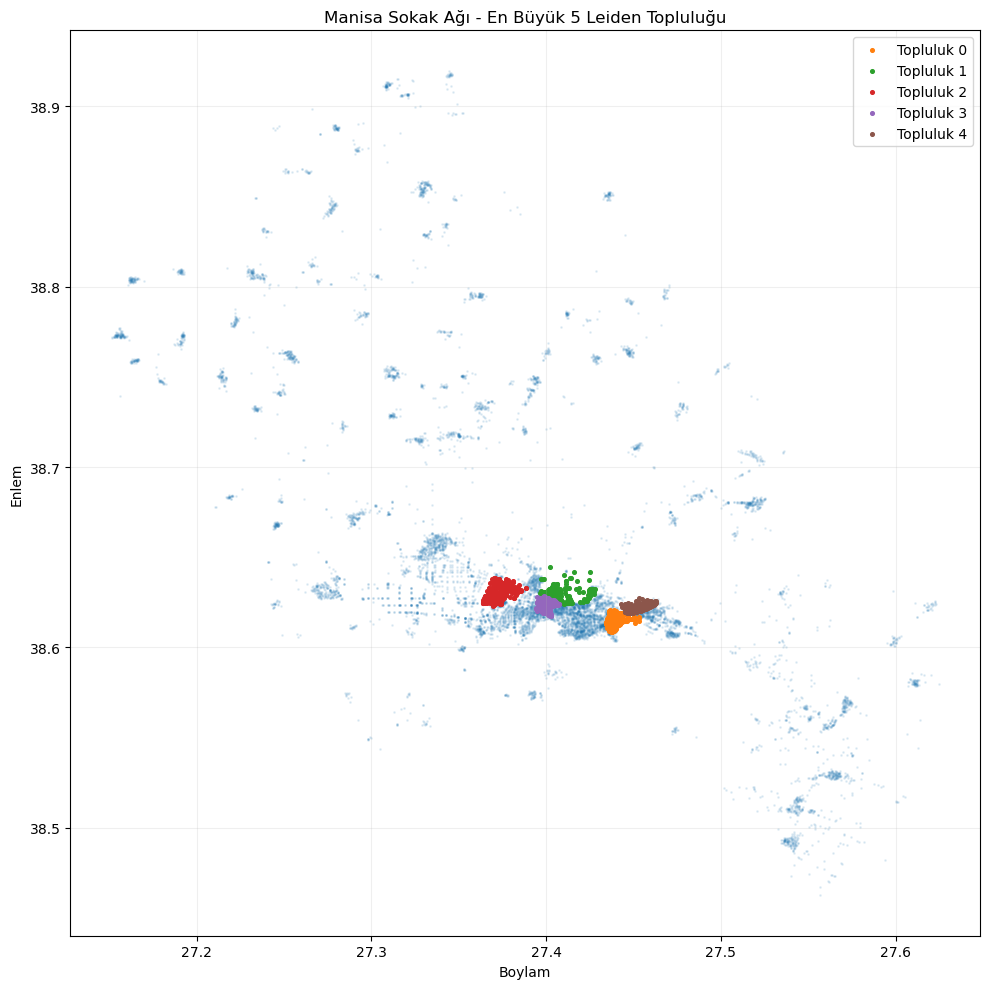

In [24]:
plt.figure(figsize=(10, 10))

# Önce bütün ağı açık şekilde arka plana koy
plt.scatter(
    nodes_geo["lon"],
    nodes_geo["lat"],
    s=1,
    alpha=0.10
)

# En büyük 5 topluluğu ayrı ayrı göster
for community_id in top5_ids:

    temp = top5_nodes[
        top5_nodes["community"] == community_id
    ]

    plt.scatter(
        temp["lon"],
        temp["lat"],
        s=7,
        label=f"Topluluk {community_id}"
    )

plt.xlabel("Boylam")
plt.ylabel("Enlem")
plt.title("Manisa Sokak Ağı - En Büyük 5 Leiden Topluluğu")
plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    "data/top5_leiden_topluluklari.png",
    dpi=300
)

plt.show()

In [25]:
community_names = {
    0: "Doğu-Güneydoğu Merkez",
    1: "Kuzey Merkez",
    2: "Batı Merkez",
    3: "Merkezi Geçiş Bölgesi",
    4: "Doğu Merkez Koridoru"
}

print("--- EN BÜYÜK 5 TOPLULUK ---")

for community_id, size in largest_communities:
    print(
        f"Topluluk {community_id}: "
        f"{community_names[community_id]} - "
        f"{size} düğüm"
    )

--- EN BÜYÜK 5 TOPLULUK ---
Topluluk 0: Doğu-Güneydoğu Merkez - 328 düğüm
Topluluk 1: Kuzey Merkez - 320 düğüm
Topluluk 2: Batı Merkez - 306 düğüm
Topluluk 3: Merkezi Geçiş Bölgesi - 305 düğüm
Topluluk 4: Doğu Merkez Koridoru - 257 düğüm


In [26]:
import networkx as nx
import numpy as np

print("Null model hazırlanıyor...")

# Gerçek ağın derece dizisi
degree_sequence = [d for _, d in H.degree()]

null_graphs = []

for seed in range(100):

    G_null = nx.configuration_model(
        degree_sequence,
        seed=seed
    )

    # MultiGraph -> normal Graph
    G_null = nx.Graph(G_null)

    # Self-loop'ları kaldır
    G_null.remove_edges_from(
        nx.selfloop_edges(G_null)
    )

    # En büyük bağlı bileşeni al
    largest_nodes = max(
        nx.connected_components(G_null),
        key=len
    )

    G_null = G_null.subgraph(
        largest_nodes
    ).copy()

    null_graphs.append(G_null)

    if (seed + 1) % 10 == 0:
        print(f"{seed + 1}/100 rastgele ağ hazır")

print("\n100 null model ağı oluşturuldu.")

Null model hazırlanıyor...
10/100 rastgele ağ hazır
20/100 rastgele ağ hazır
30/100 rastgele ağ hazır
40/100 rastgele ağ hazır
50/100 rastgele ağ hazır
60/100 rastgele ağ hazır
70/100 rastgele ağ hazır
80/100 rastgele ağ hazır
90/100 rastgele ağ hazır
100/100 rastgele ağ hazır

100 null model ağı oluşturuldu.


In [27]:
import numpy as np

print("Null modeller için kümelenme katsayıları hesaplanıyor...")

# Gerçek ağ
real_clustering = nx.average_clustering(H)

# 100 rastgele ağ
null_clustering = []

for i, G_null in enumerate(null_graphs):

    value = nx.average_clustering(G_null)
    null_clustering.append(value)

    if (i + 1) % 10 == 0:
        print(f"{i + 1}/100 tamamlandı")

null_clustering = np.array(null_clustering)

# Null model ortalama ve standart sapması
null_mean = np.mean(null_clustering)
null_std = np.std(null_clustering, ddof=1)

# Z-skoru
z_clustering = (
    real_clustering - null_mean
) / null_std

print("\n--- KÜMELENME NULL MODEL SONUCU ---")
print("Gerçek ağ kümelenmesi:", round(real_clustering, 6))
print("Null model ortalaması:", round(null_mean, 6))
print("Null model std:", round(null_std, 6))
print("Z-skoru:", round(z_clustering, 3))

Null modeller için kümelenme katsayıları hesaplanıyor...
10/100 tamamlandı
20/100 tamamlandı
30/100 tamamlandı
40/100 tamamlandı
50/100 tamamlandı
60/100 tamamlandı
70/100 tamamlandı
80/100 tamamlandı
90/100 tamamlandı
100/100 tamamlandı

--- KÜMELENME NULL MODEL SONUCU ---
Gerçek ağ kümelenmesi: 0.046464
Null model ortalaması: 0.000133
Null model std: 0.000103
Z-skoru: 447.857


In [28]:
import random
import numpy as np
import networkx as nx

def sampled_average_path_length(G, sample_size=100, seed=42):

    random.seed(seed)

    nodes = list(G.nodes())

    if len(nodes) < sample_size:
        sample_size = len(nodes)

    sample_nodes = random.sample(
        nodes,
        sample_size
    )

    distances = []

    for source in sample_nodes:

        lengths = nx.single_source_shortest_path_length(
            G,
            source
        )

        for target in sample_nodes:

            if target != source and target in lengths:
                distances.append(lengths[target])

    return np.mean(distances)

In [29]:
print("Gerçek ağın örneklemeli ortalama yolu hesaplanıyor...")

real_avg_path = sampled_average_path_length(
    H,
    sample_size=100,
    seed=42
)

print(
    "Gerçek ağ ortalama yol:",
    round(real_avg_path, 4)
)

print("\nNull modeller hesaplanıyor...")

null_avg_paths = []

for i, G_null in enumerate(null_graphs):

    value = sampled_average_path_length(
        G_null,
        sample_size=100,
        seed=42
    )

    null_avg_paths.append(value)

    if (i + 1) % 10 == 0:
        print(f"{i + 1}/100 tamamlandı")

null_avg_paths = np.array(null_avg_paths)

null_path_mean = np.mean(null_avg_paths)
null_path_std = np.std(null_avg_paths, ddof=1)

z_path = (
    real_avg_path - null_path_mean
) / null_path_std

print("\n--- ORTALAMA YOL NULL MODEL SONUCU ---")

print(
    "Gerçek ağ ortalama yol:",
    round(real_avg_path, 4)
)

print(
    "Null model ortalaması:",
    round(null_path_mean, 4)
)

print(
    "Null model std:",
    round(null_path_std, 4)
)

print(
    "Z-skoru:",
    round(z_path, 3)
)

Gerçek ağın örneklemeli ortalama yolu hesaplanıyor...
Gerçek ağ ortalama yol: 44.1681

Null modeller hesaplanıyor...
10/100 tamamlandı
20/100 tamamlandı
30/100 tamamlandı
40/100 tamamlandı
50/100 tamamlandı
60/100 tamamlandı
70/100 tamamlandı
80/100 tamamlandı
90/100 tamamlandı
100/100 tamamlandı

--- ORTALAMA YOL NULL MODEL SONUCU ---
Gerçek ağ ortalama yol: 44.1681
Null model ortalaması: 10.8489
Null model std: 0.1101
Z-skoru: 302.57


In [30]:
from networkx.algorithms.community import louvain_communities
from networkx.algorithms.community.quality import modularity
import numpy as np

# Gerçek ağdaki en yüksek Louvain modülerliği
real_modularity = max(
    run["modularity"]
    for run in louvain_runs
)

print("Gerçek ağ modülerliği:", round(real_modularity, 4))
print("\nNull model modülerlikleri hesaplanıyor...")

null_modularities = []

for i, G_null in enumerate(null_graphs):

    communities = louvain_communities(
        G_null,
        weight=None,
        seed=42
    )

    mod = modularity(
        G_null,
        communities,
        weight=None
    )

    null_modularities.append(mod)

    if (i + 1) % 10 == 0:
        print(f"{i + 1}/100 tamamlandı")

null_modularities = np.array(null_modularities)

null_mod_mean = np.mean(null_modularities)
null_mod_std = np.std(null_modularities, ddof=1)

z_modularity = (
    real_modularity - null_mod_mean
) / null_mod_std

print("\n--- MODÜLERLİK NULL MODEL SONUCU ---")

print(
    "Gerçek ağ modülerliği:",
    round(real_modularity, 4)
)

print(
    "Null model ortalaması:",
    round(null_mod_mean, 4)
)

print(
    "Null model std:",
    round(null_mod_std, 4)
)

print(
    "Z-skoru:",
    round(z_modularity, 3)
)

Gerçek ağ modülerliği: 0.9602

Null model modülerlikleri hesaplanıyor...
10/100 tamamlandı
20/100 tamamlandı
30/100 tamamlandı
40/100 tamamlandı
50/100 tamamlandı
60/100 tamamlandı
70/100 tamamlandı
80/100 tamamlandı
90/100 tamamlandı
100/100 tamamlandı

--- MODÜLERLİK NULL MODEL SONUCU ---
Gerçek ağ modülerliği: 0.9602
Null model ortalaması: 0.6887
Null model std: 0.0009
Z-skoru: 316.673


In [32]:
import osmnx as ox

ox.settings.overpass_url = "https://overpass.kumi.systems/api"
ox.settings.requests_timeout = 300
ox.settings.use_cache = True

print("Overpass sunucusu değiştirildi.")

Overpass sunucusu değiştirildi.


In [33]:
tags_test = {
    "amenity": [
        "cafe",
        "restaurant",
        "fast_food",
        "bank",
        "pharmacy",
        "marketplace"
    ]
}

print("Şehzadeler POI indiriliyor...")

poi_sehzadeler = ox.features_from_place(
    "Şehzadeler, Manisa, Turkey",
    tags=tags_test
)

print("Bulunan POI:", len(poi_sehzadeler))

Şehzadeler POI indiriliyor...


ReadTimeout: HTTPSConnectionPool(host='overpass.kumi.systems', port=443): Read timed out. (read timeout=300)

In [34]:
import osmnx as ox

ox.settings.overpass_url = "https://overpass.kumi.systems/api"
ox.settings.overpass_rate_limit = False
ox.settings.requests_timeout = 300
ox.settings.use_cache = True

print("Overpass ayarları hazır.")

Overpass ayarları hazır.


In [35]:
tags_test = {
    "amenity": [
        "cafe",
        "restaurant",
        "fast_food",
        "bank",
        "pharmacy",
        "marketplace"
    ]
}

print("Şehzadeler POI indiriliyor...")

poi_sehzadeler = ox.features_from_place(
    "Şehzadeler, Manisa, Turkey",
    tags=tags_test
)

print("Bulunan POI:", len(poi_sehzadeler))

Şehzadeler POI indiriliyor...
Bulunan POI: 111


In [37]:
ox.settings.overpass_url = "https://overpass.private.coffee/api"
ox.settings.overpass_rate_limit = False
ox.settings.requests_timeout = 300

print("Yeni Overpass sunucusu ayarlandı.")

Yeni Overpass sunucusu ayarlandı.


In [38]:
print("Yunusemre POI indiriliyor...")

poi_yunusemre = ox.features_from_place(
    "Yunusemre, Manisa, Turkey",
    tags=tags_test
)

print("Bulunan POI:", len(poi_yunusemre))

Yunusemre POI indiriliyor...


ResponseStatusCodeError: 'overpass.private.coffee' responded: 502 Bad Gateway <html>
<head><title>502 Bad Gateway</title></head>
<body>
<center><h1>502 Bad Gateway</h1></center>
<hr><center>nginx/1.26.3</center>
</body>
</html>


In [42]:
import requests
import pandas as pd
import geopandas as gpd
import numpy as np
import osmnx as ox
import time

# =============================
# 1) YUNUSEMRE SINIRINI BUL
# =============================

yun_poly = ox.geocode_to_gdf(
    "Yunusemre, Manisa, Turkey"
)

WEST, SOUTH, EAST, NORTH = yun_poly.total_bounds

print("Yunusemre sınırları:")
print("Batı:", WEST)
print("Güney:", SOUTH)
print("Doğu:", EAST)
print("Kuzey:", NORTH)


# =============================
# 2) OVERPASS SUNUCULARI
# =============================

ENDPOINTS = [
    "https://overpass.private.coffee/api/interpreter",
    "https://maps.mail.ru/osm/tools/overpass/api/interpreter",
    "https://overpass-api.de/api/interpreter"
]


# =============================
# 3) ALANI 5x5 PARÇAYA BÖL
# =============================

xs = np.linspace(WEST, EAST, 6)
ys = np.linspace(SOUTH, NORTH, 6)

tiles = []

for x in range(5):
    for y in range(5):
        tiles.append((
            ys[y],
            xs[x],
            ys[y + 1],
            xs[x + 1]
        ))


# =============================
# 4) İNDİRME FONKSİYONU
# =============================

def download_tile(south, west, north, east):

    query = f"""
    [out:json][timeout:60];
    (
      nwr["shop"]({south},{west},{north},{east});

      nwr["amenity"~"^(cafe|restaurant|fast_food|bank|pharmacy|marketplace)$"]
      ({south},{west},{north},{east});
    );
    out center tags;
    """

    for endpoint in ENDPOINTS:

        try:
            r = requests.post(
                endpoint,
                data={"data": query},
                headers={
                    "User-Agent":
                    "Manisa-Network-Analysis-Student-Project"
                },
                timeout=70
            )

            if r.status_code != 200:
                continue

            return r.json().get("elements", [])

        except Exception:
            continue

    return None


# =============================
# 5) YUNUSEMRE POI'LERİNİ ÇEK
# =============================

all_pois = {}
failed_tiles = []

for i, tile in enumerate(tiles, start=1):

    print(f"Parça {i}/25...")

    elements = download_tile(*tile)

    if elements is None:
        print("  BAŞARISIZ - sonra tekrar denenecek")
        failed_tiles.append((i, tile))
        continue

    print("  Bulunan:", len(elements))

    for el in elements:

        key = (
            el.get("type"),
            el.get("id")
        )

        tags = el.get("tags", {})

        lat = el.get("lat")
        lon = el.get("lon")

        if lat is None or lon is None:
            center = el.get("center", {})
            lat = center.get("lat")
            lon = center.get("lon")

        if lat is None or lon is None:
            continue

        all_pois[key] = {
            "osm_type": el.get("type"),
            "osm_id": el.get("id"),
            "name": tags.get("name"),
            "shop": tags.get("shop"),
            "amenity": tags.get("amenity"),
            "lat": lat,
            "lon": lon
        }

    time.sleep(1)


# =============================
# 6) HATA VERENLERİ TEKRAR DENE
# =============================

for retry in range(3):

    if not failed_tiles:
        break

    print(
        f"\n--- {retry + 1}. TEKRAR DENEME ---"
    )

    remaining = []

    for i, tile in failed_tiles:

        print(f"Parça {i} tekrar deneniyor...")

        elements = download_tile(*tile)

        if elements is None:
            print("  Yine başarısız")
            remaining.append((i, tile))
            continue

        print("  Bulunan:", len(elements))

        for el in elements:

            key = (
                el.get("type"),
                el.get("id")
            )

            tags = el.get("tags", {})

            lat = el.get("lat")
            lon = el.get("lon")

            if lat is None or lon is None:
                center = el.get("center", {})
                lat = center.get("lat")
                lon = center.get("lon")

            if lat is None or lon is None:
                continue

            all_pois[key] = {
                "osm_type": el.get("type"),
                "osm_id": el.get("id"),
                "name": tags.get("name"),
                "shop": tags.get("shop"),
                "amenity": tags.get("amenity"),
                "lat": lat,
                "lon": lon
            }

        time.sleep(2)

    failed_tiles = remaining


# =============================
# 7) DATAFRAME
# =============================

poi_yunusemre = pd.DataFrame(
    list(all_pois.values())
)

# GeoDataFrame yap
poi_yunusemre = gpd.GeoDataFrame(
    poi_yunusemre,
    geometry=gpd.points_from_xy(
        poi_yunusemre["lon"],
        poi_yunusemre["lat"]
    ),
    crs="EPSG:4326"
)

# BBOX nedeniyle Yunusemre dışına düşenleri temizle
poi_yunusemre = gpd.clip(
    poi_yunusemre,
    yun_poly
)


# =============================
# 8) SONUÇ
# =============================

print("\n==============================")
print("YUNUSEMRE POI TAMAMLANDI")
print("==============================")

print(
    "Toplam Yunusemre POI:",
    len(poi_yunusemre)
)

print(
    "Shop:",
    poi_yunusemre["shop"].notna().sum()
)

print(
    "Amenity:",
    poi_yunusemre["amenity"].notna().sum()
)

print(
    "Başarısız kalan parça:",
    len(failed_tiles)
)

poi_yunusemre.to_csv(
    "data/yunusemre_poi.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "Kaydedildi: data/yunusemre_poi.csv"
)

Yunusemre sınırları:
Batı: 27.1124124
Güney: 38.5338492
Doğu: 27.4410925
Kuzey: 38.9512557
Parça 1/25...
  Bulunan: 0
Parça 2/25...
  Bulunan: 2
Parça 3/25...
  Bulunan: 0
Parça 4/25...
  BAŞARISIZ - sonra tekrar denenecek
Parça 5/25...
  BAŞARISIZ - sonra tekrar denenecek
Parça 6/25...
  Bulunan: 1
Parça 7/25...
  Bulunan: 0
Parça 8/25...
  Bulunan: 0
Parça 9/25...
  Bulunan: 0
Parça 10/25...
  Bulunan: 0
Parça 11/25...
  BAŞARISIZ - sonra tekrar denenecek
Parça 12/25...
  Bulunan: 5
Parça 13/25...
  Bulunan: 0
Parça 14/25...
  Bulunan: 0
Parça 15/25...
  Bulunan: 0
Parça 16/25...
  Bulunan: 2
Parça 17/25...
  Bulunan: 24
Parça 18/25...
  BAŞARISIZ - sonra tekrar denenecek
Parça 19/25...
  Bulunan: 0
Parça 20/25...
  Bulunan: 0
Parça 21/25...
  Bulunan: 303
Parça 22/25...
  BAŞARISIZ - sonra tekrar denenecek
Parça 23/25...
  Bulunan: 0
Parça 24/25...
  Bulunan: 0
Parça 25/25...
  Bulunan: 0

--- 1. TEKRAR DENEME ---
Parça 4 tekrar deneniyor...
  Bulunan: 0
Parça 5 tekrar deneniyor...


In [44]:
import requests
import pandas as pd
import geopandas as gpd
import numpy as np
import osmnx as ox
import time

# -----------------------------
# ŞEHZADELER SINIRI
# -----------------------------

seh_poly = ox.geocode_to_gdf(
    "Şehzadeler, Manisa, Turkey"
)

WEST, SOUTH, EAST, NORTH = seh_poly.total_bounds

# 4x4 küçük parçaya böl
xs = np.linspace(WEST, EAST, 5)
ys = np.linspace(SOUTH, NORTH, 5)

tiles = []

for x in range(4):
    for y in range(4):
        tiles.append((
            ys[y],
            xs[x],
            ys[y + 1],
            xs[x + 1]
        ))


ENDPOINTS = [
    "https://overpass.private.coffee/api/interpreter",
    "https://maps.mail.ru/osm/tools/overpass/api/interpreter",
    "https://overpass-api.de/api/interpreter"
]


# -----------------------------
# SADECE SHOP İNDİR
# -----------------------------

def download_shop(south, west, north, east):

    query = f"""
    [out:json][timeout:60];
    (
      nwr["shop"]({south},{west},{north},{east});
    );
    out center tags;
    """

    for endpoint in ENDPOINTS:

        try:
            r = requests.post(
                endpoint,
                data={"data": query},
                headers={
                    "User-Agent":
                    "Manisa-Network-Analysis-Student-Project"
                },
                timeout=70
            )

            if r.status_code != 200:
                continue

            return r.json().get("elements", [])

        except Exception:
            continue

    return None


shop_records = {}
failed = []

for i, tile in enumerate(tiles, start=1):

    print(f"Şehzadeler shop parça {i}/16...")

    elements = download_shop(*tile)

    if elements is None:
        print("  BAŞARISIZ")
        failed.append((i, tile))
        continue

    print("  Bulunan:", len(elements))

    for el in elements:

        key = (el.get("type"), el.get("id"))
        tags = el.get("tags", {})

        lat = el.get("lat")
        lon = el.get("lon")

        if lat is None or lon is None:
            center = el.get("center", {})
            lat = center.get("lat")
            lon = center.get("lon")

        if lat is None or lon is None:
            continue

        shop_records[key] = {
            "osm_type": el.get("type"),
            "osm_id": el.get("id"),
            "name": tags.get("name"),
            "shop": tags.get("shop"),
            "amenity": None,
            "lat": lat,
            "lon": lon
        }

    time.sleep(1)


# Başarısız parçaları tekrar dene
for retry in range(2):

    if not failed:
        break

    remaining = []

    print(f"\n--- {retry + 1}. TEKRAR ---")

    for i, tile in failed:

        elements = download_shop(*tile)

        if elements is None:
            remaining.append((i, tile))
            continue

        for el in elements:

            key = (el.get("type"), el.get("id"))
            tags = el.get("tags", {})

            lat = el.get("lat")
            lon = el.get("lon")

            if lat is None or lon is None:
                center = el.get("center", {})
                lat = center.get("lat")
                lon = center.get("lon")

            if lat is None or lon is None:
                continue

            shop_records[key] = {
                "osm_type": el.get("type"),
                "osm_id": el.get("id"),
                "name": tags.get("name"),
                "shop": tags.get("shop"),
                "amenity": None,
                "lat": lat,
                "lon": lon
            }

    failed = remaining


shop_sehzadeler = pd.DataFrame(
    list(shop_records.values())
)

shop_sehzadeler = gpd.GeoDataFrame(
    shop_sehzadeler,
    geometry=gpd.points_from_xy(
        shop_sehzadeler["lon"],
        shop_sehzadeler["lat"]
    ),
    crs="EPSG:4326"
)

shop_sehzadeler = gpd.clip(
    shop_sehzadeler,
    seh_poly
)

print("\n==========================")
print("ŞEHZADELER SHOP TAMAMLANDI")
print("==========================")

print("Bulunan shop:", len(shop_sehzadeler))
print("Başarısız parça:", len(failed))

Şehzadeler shop parça 1/16...
  BAŞARISIZ
Şehzadeler shop parça 2/16...
  Bulunan: 168
Şehzadeler shop parça 3/16...
  Bulunan: 0
Şehzadeler shop parça 4/16...
  Bulunan: 0
Şehzadeler shop parça 5/16...
  Bulunan: 0
Şehzadeler shop parça 6/16...
  Bulunan: 1
Şehzadeler shop parça 7/16...
  BAŞARISIZ
Şehzadeler shop parça 8/16...
  Bulunan: 0
Şehzadeler shop parça 9/16...
  Bulunan: 0
Şehzadeler shop parça 10/16...
  Bulunan: 1
Şehzadeler shop parça 11/16...
  Bulunan: 0
Şehzadeler shop parça 12/16...
  BAŞARISIZ
Şehzadeler shop parça 13/16...
  BAŞARISIZ
Şehzadeler shop parça 14/16...
  Bulunan: 0
Şehzadeler shop parça 15/16...
  Bulunan: 1
Şehzadeler shop parça 16/16...
  Bulunan: 0

--- 1. TEKRAR ---

--- 2. TEKRAR ---

ŞEHZADELER SHOP TAMAMLANDI
Bulunan shop: 84
Başarısız parça: 1


In [45]:
import pandas as pd
import geopandas as gpd
import numpy as np

# ---------------------------------
# ESKİ ŞEHZADELER 111 AMENITY VERİSİ
# ---------------------------------

seh_old = poi_sehzadeler.copy()

# Nokta olmayan geometriler için merkez noktası oluştur
seh_projected = seh_old.to_crs(
    seh_old.estimate_utm_crs()
)

seh_centroids = (
    seh_projected.geometry
    .centroid
    .to_crs("EPSG:4326")
)

seh_reset = seh_old.reset_index()

# OSMnx sürümüne göre sütun isimleri değişebiliyor
type_col = (
    "element"
    if "element" in seh_reset.columns
    else "element_type"
)

id_col = (
    "id"
    if "id" in seh_reset.columns
    else "osmid"
)

seh_amenity = pd.DataFrame({
    "osm_type": seh_reset[type_col],
    "osm_id": seh_reset[id_col],
    "name": seh_reset["name"] if "name" in seh_reset.columns else None,
    "shop": None,
    "amenity": seh_reset["amenity"] if "amenity" in seh_reset.columns else None,
    "lat": seh_centroids.y.values,
    "lon": seh_centroids.x.values
})


# ---------------------------------
# ŞEHZADELER SHOP VERİSİ
# ---------------------------------

seh_shop = shop_sehzadeler[
    [
        "osm_type",
        "osm_id",
        "name",
        "shop",
        "amenity",
        "lat",
        "lon"
    ]
].copy()


# ---------------------------------
# YUNUSEMRE
# ---------------------------------

yun = poi_yunusemre[
    [
        "osm_type",
        "osm_id",
        "name",
        "shop",
        "amenity",
        "lat",
        "lon"
    ]
].copy()


# ---------------------------------
# ÜÇ VERİYİ BİRLEŞTİR
# ---------------------------------

poi_all = pd.concat(
    [
        seh_amenity,
        seh_shop,
        yun
    ],
    ignore_index=True
)

# Aynı OSM noktası iki sorguda geldiyse tek kayıt bırak
poi_all = poi_all.drop_duplicates(
    subset=["osm_type", "osm_id"]
).reset_index(drop=True)

print("--- BİRLEŞTİRİLMİŞ POI ---")
print("Toplam benzersiz POI:", len(poi_all))
print("Shop:", poi_all["shop"].notna().sum())
print("Amenity:", poi_all["amenity"].notna().sum())

poi_all.to_csv(
    "data/manisa_poi.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nKaydedildi: data/manisa_poi.csv")

--- BİRLEŞTİRİLMİŞ POI ---
Toplam benzersiz POI: 429
Shop: 198
Amenity: 231

Kaydedildi: data/manisa_poi.csv


In [47]:
from scipy.spatial import cKDTree

# Kavşakları GeoDataFrame yap
node_poi = nodes_geo.copy()

node_gdf = gpd.GeoDataFrame(
    node_poi,
    geometry=gpd.points_from_xy(
        node_poi["lon"],
        node_poi["lat"]
    ),
    crs="EPSG:4326"
)

# POI GeoDataFrame
poi_gdf = gpd.GeoDataFrame(
    poi_all,
    geometry=gpd.points_from_xy(
        poi_all["lon"],
        poi_all["lat"]
    ),
    crs="EPSG:4326"
)

# Metre ile hesap yapmak için uygun UTM projeksiyonu
utm_crs = node_gdf.estimate_utm_crs()

node_proj = node_gdf.to_crs(utm_crs)
poi_proj = poi_gdf.to_crs(utm_crs)

# POI koordinat ağacı
poi_xy = np.column_stack([
    poi_proj.geometry.x,
    poi_proj.geometry.y
])

node_xy = np.column_stack([
    node_proj.geometry.x,
    node_proj.geometry.y
])

tree = cKDTree(poi_xy)

# Her kavşağın 500 metre çevresindeki POI'ler
neighbors = tree.query_ball_point(
    node_xy,
    r=500
)

poi_counts = [
    len(x)
    for x in neighbors
]

node_gdf["poi_500m"] = poi_counts

print("--- POI YOĞUNLUĞU ---")
print(
    "Ortalama POI / 500 m:",
    round(node_gdf["poi_500m"].mean(), 2)
)

print(
    "En yüksek POI / 500 m:",
    node_gdf["poi_500m"].max()
)

print(
    "POI bulunan kavşak sayısı:",
    (node_gdf["poi_500m"] > 0).sum()
)

--- POI YOĞUNLUĞU ---
Ortalama POI / 500 m: 7.18
En yüksek POI / 500 m: 121
POI bulunan kavşak sayısı: 4802


In [48]:
# node_id türlerini eşitle
node_gdf["node_id"] = node_gdf["node_id"].astype(str)

centrality_temp = centrality_df.copy()
centrality_temp["node_id"] = centrality_temp["node_id"].astype(str)

# Merkeziyet + POI yoğunluğunu birleştir
poi_analysis = centrality_temp.merge(
    node_gdf[
        ["node_id", "lon", "lat", "poi_500m"]
    ],
    on="node_id",
    how="left"
)

# Spearman korelasyonu
from scipy.stats import spearmanr

rho, p_value = spearmanr(
    poi_analysis["betweenness"],
    poi_analysis["poi_500m"]
)

print("--- BETWENNESS - POI İLİŞKİSİ ---")
print("Spearman rho:", round(rho, 4))
print("p-değeri:", p_value)

# Kaydet
poi_analysis.to_csv(
    "data/poi_betweenness_analysis.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Kaydedildi: data/poi_betweenness_analysis.csv")

--- BETWENNESS - POI İLİŞKİSİ ---
Spearman rho: 0.2096
p-değeri: 5.3925913333831284e-111
Kaydedildi: data/poi_betweenness_analysis.csv


In [49]:
# Kenar betweenness ile en kritik yolları bul

print("Kritik yollar hesaplanıyor...")

edge_bet = nx.edge_betweenness_centrality(
    H,
    k=300,
    normalized=True,
    weight="length_m",
    seed=42
)

top10_edges = sorted(
    edge_bet.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

print("\n--- EN KRİTİK 10 YOL ---")

for i, ((u, v), score) in enumerate(top10_edges, start=1):
    print(
        f"{i}. {u} - {v} "
        f"| betweenness = {score:.6f}"
    )

Kritik yollar hesaplanıyor...

--- EN KRİTİK 10 YOL ---
1. 2251603222 - 2251420435 | betweenness = 0.004552
2. 2251463963 - 2251603222 | betweenness = 0.004486
3. 2249636291 - 2351998437 | betweenness = 0.004209
4. 12997816396 - 2251420435 | betweenness = 0.004155
5. 2351998437 - 2249731472 | betweenness = 0.004109
6. 1872287837 - 1872287833 | betweenness = 0.004101
7. 2351998467 - 1872287837 | betweenness = 0.004101
8. 10570566697 - 2674351759 | betweenness = 0.004089
9. 983383019 - 2351998468 | betweenness = 0.004085
10. 1872287833 - 2345240568 | betweenness = 0.004075


In [50]:
import networkx as nx
import numpy as np
import pandas as pd
import random

SEED = 42
random.seed(SEED)

# Aynı 150 düğüm bütün senaryolarda kullanılacak
scenario_nodes = random.sample(
    list(H.nodes()),
    150
)

def accessibility_metrics(G, sample_nodes):
    
    distances = []
    disconnected = 0
    total_pairs = 0

    for i, source in enumerate(sample_nodes):

        lengths = nx.single_source_dijkstra_path_length(
            G,
            source,
            weight="length_m"
        )

        for target in sample_nodes[i + 1:]:

            total_pairs += 1

            if target in lengths:
                distances.append(lengths[target])
            else:
                disconnected += 1

    return {
        "avg_distance_m": np.mean(distances),
        "disconnected_pairs": disconnected,
        "total_pairs": total_pairs,
        "disconnected_pct": (
            disconnected / total_pairs * 100
        )
    }


# ------------------------------------
# NORMAL DURUM
# ------------------------------------

print("Normal ağ hesaplanıyor...")

baseline = accessibility_metrics(
    H,
    scenario_nodes
)

print(
    "Normal ortalama mesafe:",
    round(baseline["avg_distance_m"] / 1000, 2),
    "km"
)

print(
    "Normal kopuk çift oranı:",
    round(baseline["disconnected_pct"], 3),
    "%"
)


# ------------------------------------
# KRİTİK 10 YOLU TEK TEK KALDIR
# ------------------------------------

results = []

print("\nKritik yol senaryoları başlıyor...\n")

for rank, ((u, v), edge_score) in enumerate(
    top10_edges,
    start=1
):

    G_test = H.copy()

    # Yol bilgilerini kaldırmadan önce al
    edge_data = G_test.get_edge_data(u, v)

    road_name = ""
    highway = ""

    if edge_data:
        road_name = edge_data.get("name", "")
        highway = edge_data.get("highway", "")

    # Kritik yolu kaldır
    G_test.remove_edge(u, v)

    metrics = accessibility_metrics(
        G_test,
        scenario_nodes
    )

    distance_change_pct = (
        (
            metrics["avg_distance_m"]
            - baseline["avg_distance_m"]
        )
        / baseline["avg_distance_m"]
        * 100
    )

    results.append({
        "sira": rank,
        "u": u,
        "v": v,
        "yol_adi": road_name,
        "yol_turu": highway,
        "edge_betweenness": edge_score,
        "ortalama_mesafe_km":
            metrics["avg_distance_m"] / 1000,
        "mesafe_artis_yuzde":
            distance_change_pct,
        "kopuk_cift":
            metrics["disconnected_pairs"],
        "kopuk_cift_yuzde":
            metrics["disconnected_pct"]
    })

    print(
        f"{rank}/10 tamamlandı | "
        f"Mesafe değişimi: "
        f"{distance_change_pct:.3f}% | "
        f"Kopuk çift: "
        f"{metrics['disconnected_pairs']}"
    )


critical_results = pd.DataFrame(results)

print("\n--- KRİTİK YOL KESİNTİ SONUÇLARI ---")

display(
    critical_results[
        [
            "sira",
            "yol_adi",
            "edge_betweenness",
            "mesafe_artis_yuzde",
            "kopuk_cift",
            "kopuk_cift_yuzde"
        ]
    ]
)

critical_results.to_csv(
    "data/kritik_yol_senaryolari.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "\nKaydedildi: "
    "data/kritik_yol_senaryolari.csv"
)

Normal ağ hesaplanıyor...
Normal ortalama mesafe: 16.65 km
Normal kopuk çift oranı: 0.0 %

Kritik yol senaryoları başlıyor...

1/10 tamamlandı | Mesafe değişimi: 0.075% | Kopuk çift: 0
2/10 tamamlandı | Mesafe değişimi: 0.109% | Kopuk çift: 0
3/10 tamamlandı | Mesafe değişimi: 0.010% | Kopuk çift: 0
4/10 tamamlandı | Mesafe değişimi: 0.002% | Kopuk çift: 0
5/10 tamamlandı | Mesafe değişimi: 0.010% | Kopuk çift: 0
6/10 tamamlandı | Mesafe değişimi: 0.024% | Kopuk çift: 0
7/10 tamamlandı | Mesafe değişimi: 0.024% | Kopuk çift: 0
8/10 tamamlandı | Mesafe değişimi: 0.044% | Kopuk çift: 0
9/10 tamamlandı | Mesafe değişimi: 0.013% | Kopuk çift: 0
10/10 tamamlandı | Mesafe değişimi: 0.021% | Kopuk çift: 0

--- KRİTİK YOL KESİNTİ SONUÇLARI ---


,sira,yol_adi,edge_betweenness,mesafe_artis_yuzde,kopuk_cift,kopuk_cift_yuzde
0,1,,0.004552,0.074801,0,0.0
1,2,,0.004486,0.108582,0,0.0
2,3,,0.004209,0.010238,0,0.0
3,4,,0.004155,0.002321,0,0.0
4,5,,0.004109,0.009542,0,0.0
5,6,,0.004101,0.024320,0,0.0
6,7,,0.004101,0.024320,0,0.0
7,8,,0.004089,0.043958,0,0.0
8,9,,0.004085,0.013023,0,0.0
9,10,,0.004075,0.020886,0,0.0



Kaydedildi: data/kritik_yol_senaryolari.csv


In [51]:
edges_full = pd.read_csv("data/manisa_edges.csv")

edges_full["source"] = edges_full["source"].astype(str)
edges_full["target"] = edges_full["target"].astype(str)

critical_results["u"] = critical_results["u"].astype(str)
critical_results["v"] = critical_results["v"].astype(str)

def find_road_name(row):
    u = row["u"]
    v = row["v"]

    match = edges_full[
        (
            (edges_full["source"] == u) &
            (edges_full["target"] == v)
        )
        |
        (
            (edges_full["source"] == v) &
            (edges_full["target"] == u)
        )
    ]

    if len(match) > 0:
        return match.iloc[0]["name"]

    return "İsimsiz yol"

critical_results["yol_adi"] = critical_results.apply(
    find_road_name,
    axis=1
)

sonuc = critical_results.sort_values(
    "mesafe_artis_yuzde",
    ascending=False
)

display(
    sonuc[
        [
            "sira",
            "yol_adi",
            "u",
            "v",
            "mesafe_artis_yuzde",
            "kopuk_cift_yuzde"
        ]
    ]
)

,sira,yol_adi,u,v,mesafe_artis_yuzde,kopuk_cift_yuzde
1,2,NaN,2251463963,2251603222,0.108582,0.0
0,1,NaN,2251603222,2251420435,0.074801,0.0
7,8,NaN,10570566697,2674351759,0.043958,0.0
5,6,Mehmetçik Caddesi,1872287837,1872287833,0.024320,0.0
6,7,Mehmetçik Caddesi,2351998467,1872287837,0.024320,0.0
9,10,Mehmetçik Caddesi,1872287833,2345240568,0.020886,0.0
8,9,Mehmetçik Caddesi,983383019,2351998468,0.013023,0.0
2,3,Mehmetçik Caddesi,2249636291,2351998437,0.010238,0.0
4,5,Mehmetçik Caddesi,2351998437,2249731472,0.009542,0.0
3,4,NaN,12997816396,2251420435,0.002321,0.0


In [52]:
critical_results["yol_adi"] = (
    critical_results["yol_adi"]
    .fillna("İsimsiz yol (OSM'de ad yok)")
)

sonuc = critical_results.sort_values(
    "mesafe_artis_yuzde",
    ascending=False
)

sonuc.to_csv(
    "data/kritik_yol_sonuclari_final.csv",
    index=False,
    encoding="utf-8-sig"
)

display(
    sonuc[
        [
            "sira",
            "yol_adi",
            "u",
            "v",
            "mesafe_artis_yuzde",
            "kopuk_cift_yuzde"
        ]
    ]
)

,sira,yol_adi,u,v,mesafe_artis_yuzde,kopuk_cift_yuzde
1,2,İsimsiz yol (OSM'de ad yok),2251463963,2251603222,0.108582,0.0
0,1,İsimsiz yol (OSM'de ad yok),2251603222,2251420435,0.074801,0.0
7,8,İsimsiz yol (OSM'de ad yok),10570566697,2674351759,0.043958,0.0
5,6,Mehmetçik Caddesi,1872287837,1872287833,0.024320,0.0
6,7,Mehmetçik Caddesi,2351998467,1872287837,0.024320,0.0
9,10,Mehmetçik Caddesi,1872287833,2345240568,0.020886,0.0
8,9,Mehmetçik Caddesi,983383019,2351998468,0.013023,0.0
2,3,Mehmetçik Caddesi,2249636291,2351998437,0.010238,0.0
4,5,Mehmetçik Caddesi,2351998437,2249731472,0.009542,0.0
3,4,İsimsiz yol (OSM'de ad yok),12997816396,2251420435,0.002321,0.0


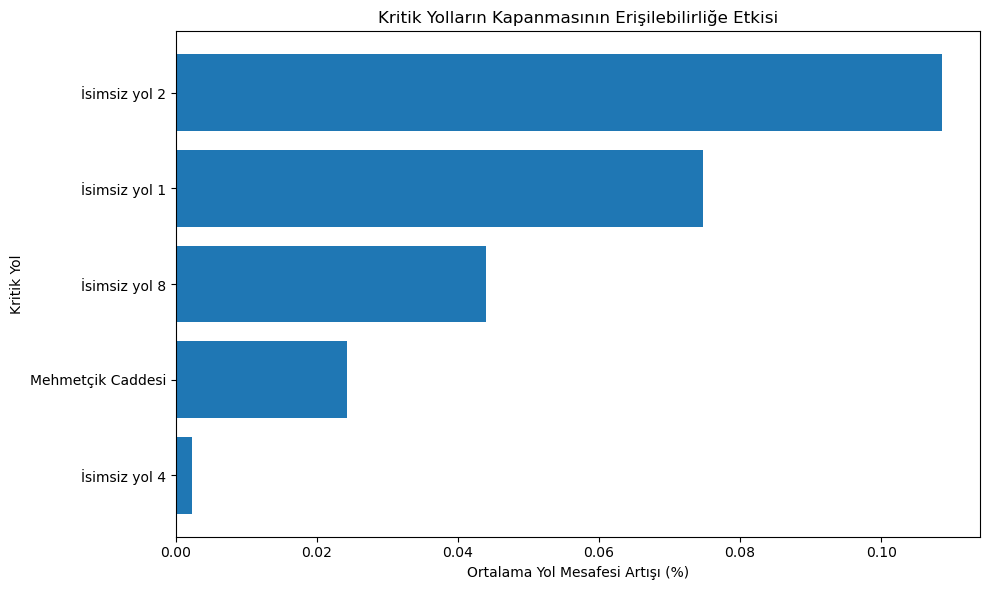

In [53]:
import matplotlib.pyplot as plt

plot_data = sonuc.copy()

plot_data["etiket"] = plot_data.apply(
    lambda row:
    row["yol_adi"]
    if "İsimsiz" not in row["yol_adi"]
    else f"İsimsiz yol {row['sira']}",
    axis=1
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["etiket"],
    plot_data["mesafe_artis_yuzde"]
)

plt.xlabel("Ortalama Yol Mesafesi Artışı (%)")
plt.ylabel("Kritik Yol")
plt.title("Kritik Yolların Kapanmasının Erişilebilirliğe Etkisi")

plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    "data/kritik_yollar_etki.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

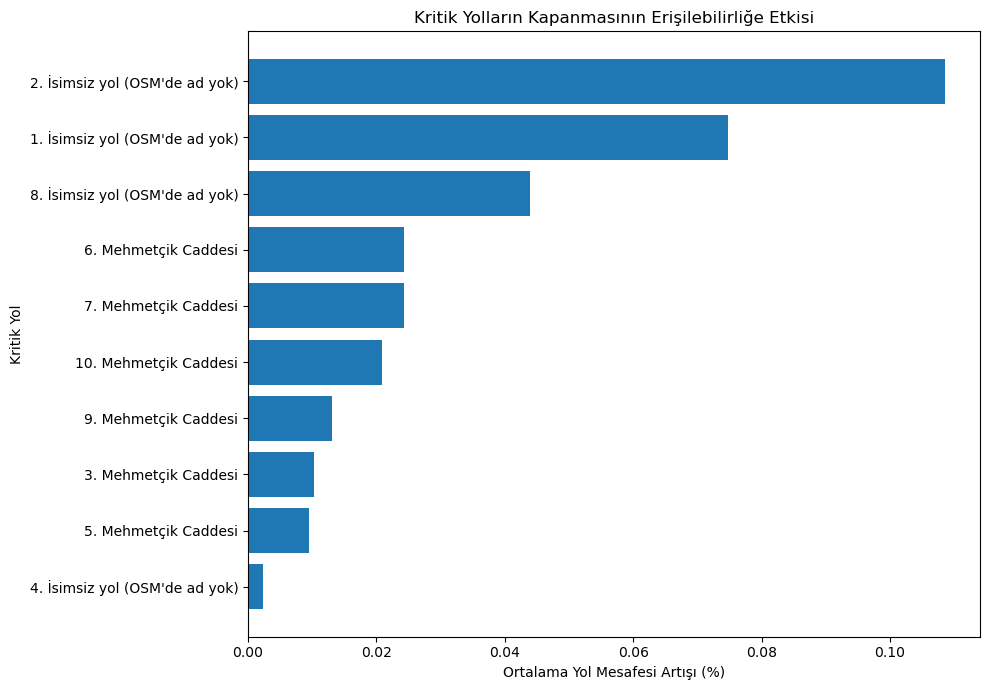

In [54]:
import matplotlib.pyplot as plt

plot_data = sonuc.copy()

# Her kenara benzersiz etiket ver
plot_data["etiket"] = plot_data.apply(
    lambda row: (
        f"{int(row['sira'])}. {row['yol_adi']}"
    ),
    axis=1
)

plt.figure(figsize=(10, 7))

plt.barh(
    plot_data["etiket"],
    plot_data["mesafe_artis_yuzde"]
)

plt.xlabel("Ortalama Yol Mesafesi Artışı (%)")
plt.ylabel("Kritik Yol")
plt.title("Kritik Yolların Kapanmasının Erişilebilirliğe Etkisi")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig(
    "data/kritik_yollar_etki.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Koordinatı bulunan düğüm: 11152
Toplam düğüm: 11152


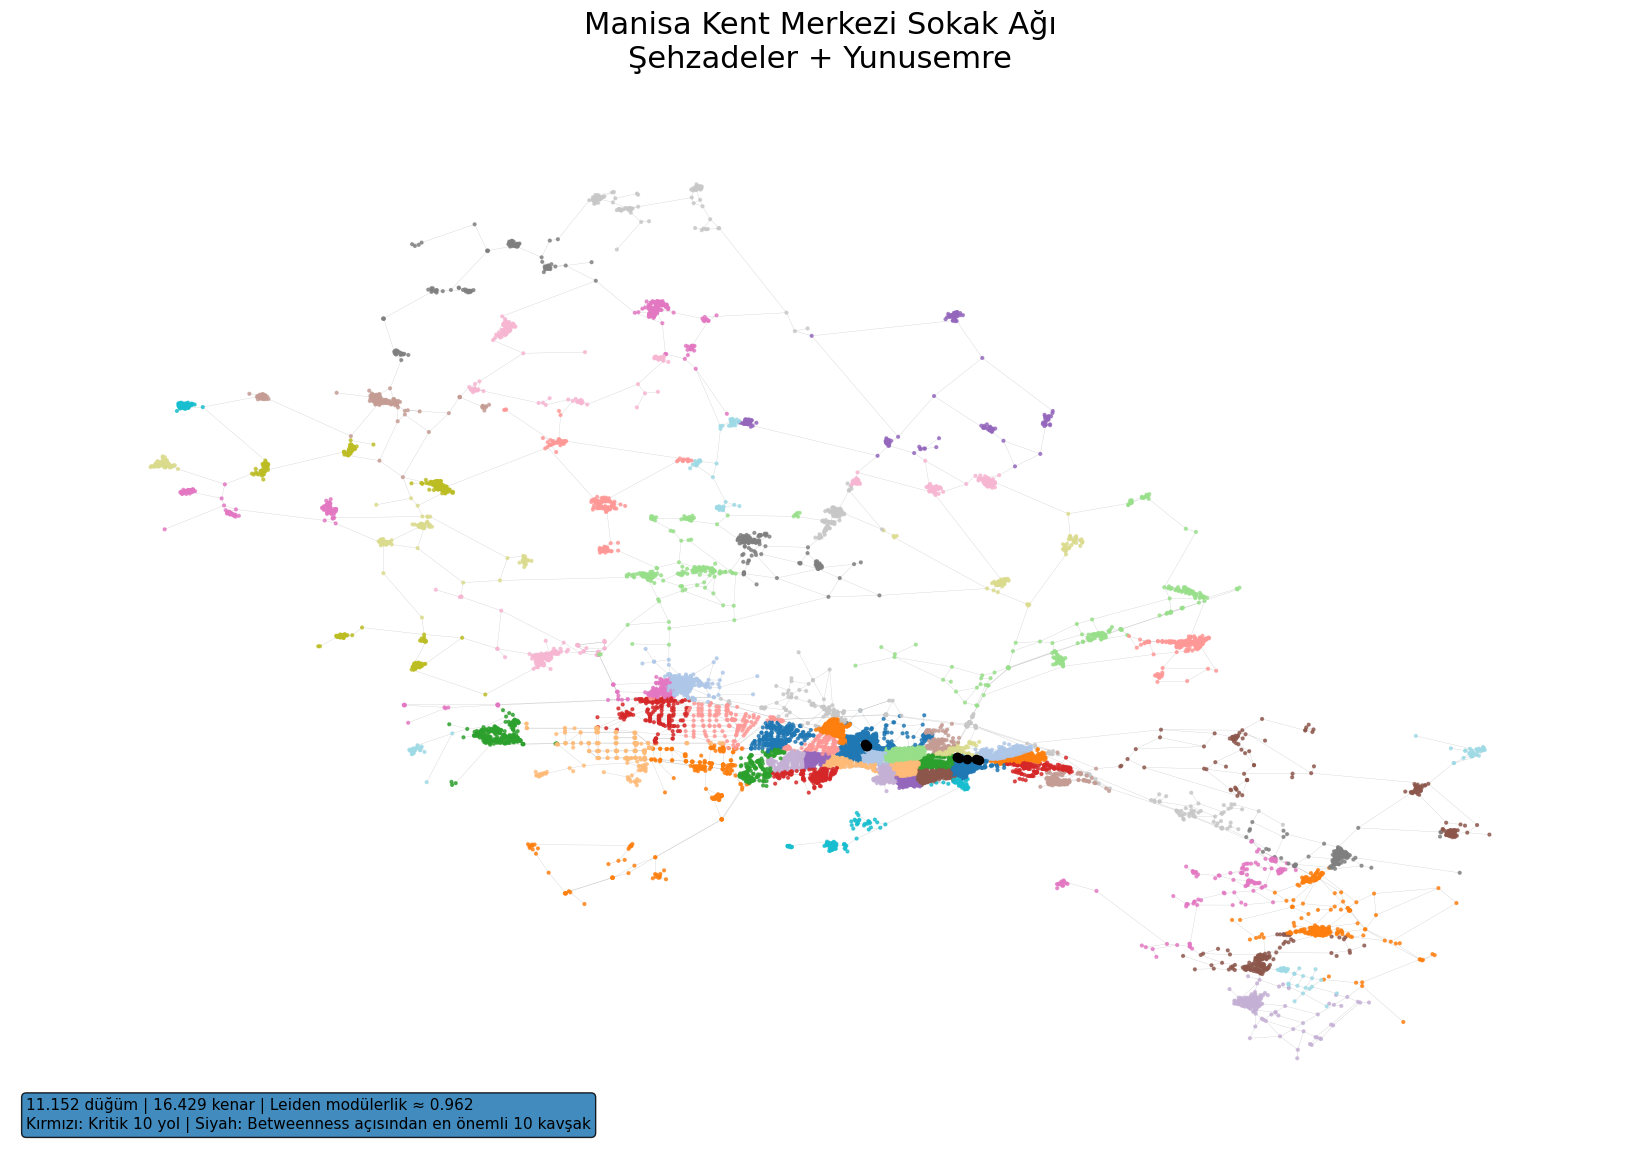

In [57]:
import matplotlib.pyplot as plt
import networkx as nx

# node_id tiplerini eşitle
nodes_geo["node_id"] = nodes_geo["node_id"].astype(str)

# H içindeki node ID -> koordinat eşleştirmesi
coord_lookup = nodes_geo.set_index("node_id")[["lon", "lat"]].to_dict("index")

pos = {}

for n in H.nodes():
    key = str(n)

    if key in coord_lookup:
        pos[n] = (
            coord_lookup[key]["lon"],
            coord_lookup[key]["lat"]
        )

print("Koordinatı bulunan düğüm:", len(pos))
print("Toplam düğüm:", H.number_of_nodes())


# ----------------------------
# LEIDEN TOPLULUKLARI
# ----------------------------

community_map_poster = {
    node: best_membership[i]
    for i, node in enumerate(node_list)
}

node_colors = [
    community_map_poster.get(node, -1)
    for node in H.nodes()
]


# ----------------------------
# A3 POSTER
# ----------------------------

fig, ax = plt.subplots(
    figsize=(16.5, 11.7)
)

# Tüm yollar
nx.draw_networkx_edges(
    H,
    pos,
    ax=ax,
    width=0.25,
    alpha=0.20
)

# Düğümler / topluluklar
nx.draw_networkx_nodes(
    H,
    pos,
    ax=ax,
    node_size=4,
    node_color=node_colors,
    cmap="tab20",
    alpha=0.75
)

# Kritik 10 yol
critical_edge_list = [
    edge
    for edge, score in top10_edges
]

nx.draw_networkx_edges(
    H,
    pos,
    edgelist=critical_edge_list,
    ax=ax,
    width=2.5,
    edge_color="red",
    alpha=0.95
)

# Betweenness'e göre en önemli 10 kavşak
top_nodes = (
    centrality_df
    .sort_values(
        "betweenness",
        ascending=False
    )
    .head(10)["node_id"]
    .tolist()
)

# Tip eşleşmesi için
top_nodes = [
    n for n in top_nodes
    if n in H.nodes()
]

nx.draw_networkx_nodes(
    H,
    pos,
    nodelist=top_nodes,
    ax=ax,
    node_size=35,
    node_color="black"
)

ax.set_title(
    "Manisa Kent Merkezi Sokak Ağı\n"
    "Şehzadeler + Yunusemre",
    fontsize=22,
    pad=18
)

ax.text(
    0.01,
    0.02,
    "11.152 düğüm | 16.429 kenar | "
    "Leiden modülerlik ≈ 0.962\n"
    "Kırmızı: Kritik 10 yol | "
    "Siyah: Betweenness açısından en önemli 10 kavşak",
    transform=ax.transAxes,
    fontsize=11,
    bbox=dict(
        boxstyle="round",
        alpha=0.85
    )
)

ax.axis("off")

plt.tight_layout()

plt.savefig(
    "data/manisa_ag_posteri_A3.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.savefig(
    "data/manisa_ag_posteri_A3.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [58]:
import json
import pandas as pd

# Betweenness'e göre en önemli 1200 düğüm
selected_nodes = set(
    centrality_df
    .sort_values("betweenness", ascending=False)
    .head(1200)["node_id"]
    .tolist()
)

# Kritik 10 yolun uçlarını da mutlaka ekle
for (u, v), score in top10_edges:
    selected_nodes.add(u)
    selected_nodes.add(v)

H_vis = H.subgraph(selected_nodes).copy()

print("Etkileşimli ağ düğüm:", H_vis.number_of_nodes())
print("Etkileşimli ağ kenar:", H_vis.number_of_edges())

Etkileşimli ağ düğüm: 1200
Etkileşimli ağ kenar: 1306


In [59]:
import json
import math
import pandas as pd
from IPython.display import FileLink, display

# =========================================================
# 1) YARDIMCI TABLOLAR
# =========================================================

# Merkeziyet bilgileri
cent_lookup = {}

for _, row in centrality_df.iterrows():
    cent_lookup[str(row["node_id"])] = {
        "degree": float(row["degree"]),
        "betweenness": float(row["betweenness"]),
        "closeness": float(row["closeness"]),
        "pagerank": float(row["pagerank"])
    }

# POI bilgileri
poi_lookup = {}

for _, row in poi_analysis.iterrows():
    poi_lookup[str(row["node_id"])] = int(
        row["poi_500m"]
    )

# Koordinatlar
coord_lookup2 = {}

for _, row in nodes_geo.iterrows():
    coord_lookup2[str(row["node_id"])] = {
        "lon": float(row["lon"]),
        "lat": float(row["lat"])
    }

# Yol isimleri
edge_name_lookup = {}

for _, row in edges_full.iterrows():

    u = str(row["source"])
    v = str(row["target"])

    name = row["name"]

    if pd.isna(name):
        name = "İsimsiz yol"

    edge_name_lookup[(u, v)] = str(name)
    edge_name_lookup[(v, u)] = str(name)


# Kritik 10 yol
critical_edge_set = {
    frozenset((str(u), str(v)))
    for (u, v), score in top10_edges
}


# =========================================================
# 2) CYTOSCAPE NODE'LARI
# =========================================================

nodes_json = []

# Koordinat ölçekleme
selected_coords = [
    coord_lookup2[str(n)]
    for n in H_vis.nodes()
    if str(n) in coord_lookup2
]

min_lon = min(x["lon"] for x in selected_coords)
max_lat = max(x["lat"] for x in selected_coords)

SCALE = 25000

for node in H_vis.nodes():

    node_id = str(node)

    coords = coord_lookup2[node_id]

    community = int(
        community_map_poster.get(node, -1)
    )

    cent = cent_lookup.get(
        node_id,
        {
            "degree": 0,
            "betweenness": 0,
            "closeness": 0,
            "pagerank": 0
        }
    )

    poi_count = poi_lookup.get(
        node_id,
        0
    )

    # Topluluk için deterministik renk
    hue = (community * 137) % 360
    color = f"hsl({hue}, 65%, 52%)"

    x = (
        coords["lon"] - min_lon
    ) * SCALE

    y = (
        max_lat - coords["lat"]
    ) * SCALE

    nodes_json.append({
        "data": {
            "id": node_id,
            "label": node_id,
            "community": community,
            "betweenness": round(
                cent["betweenness"], 6
            ),
            "degree": round(
                cent["degree"], 6
            ),
            "closeness": round(
                cent["closeness"], 6
            ),
            "pagerank": round(
                cent["pagerank"], 8
            ),
            "poi": poi_count,
            "lon": round(coords["lon"], 6),
            "lat": round(coords["lat"], 6),
            "color": color
        },
        "position": {
            "x": x,
            "y": y
        }
    })


# =========================================================
# 3) CYTOSCAPE EDGE'LERİ
# =========================================================

edges_json = []

for i, (u, v, data) in enumerate(
    H_vis.edges(data=True)
):

    su = str(u)
    sv = str(v)

    critical = (
        frozenset((su, sv))
        in critical_edge_set
    )

    road_name = edge_name_lookup.get(
        (su, sv),
        "İsimsiz yol"
    )

    edges_json.append({
        "data": {
            "id": f"e{i}",
            "source": su,
            "target": sv,
            "road": road_name,
            "length": round(
                float(data.get("length_m", 0)),
                1
            ),
            "critical": "yes" if critical else "no"
        }
    })


elements = nodes_json + edges_json

communities = sorted({
    int(
        community_map_poster.get(n, -1)
    )
    for n in H_vis.nodes()
})


elements_json = json.dumps(
    elements,
    ensure_ascii=False
).replace("</", "<\\/")

communities_json = json.dumps(
    communities
)


# =========================================================
# 4) HTML
# =========================================================

html = """
<!DOCTYPE html>
<html lang="tr">
<head>

<meta charset="UTF-8">

<meta name="viewport"
content="width=device-width, initial-scale=1.0">

<title>Manisa Sokak Ağı</title>

<script src="https://unpkg.com/cytoscape@3.30.4/dist/cytoscape.min.js"></script>

<style>

* {
    box-sizing: border-box;
}

body {
    margin: 0;
    font-family: Arial, sans-serif;
    background: #f4f6f8;
    color: #1f2937;
}

header {
    background: #111827;
    color: white;
    padding: 18px 24px;
}

header h1 {
    margin: 0 0 6px 0;
    font-size: 24px;
}

header p {
    margin: 0;
    color: #d1d5db;
}

.controls {
    display: flex;
    gap: 12px;
    padding: 14px;
    background: white;
    border-bottom: 1px solid #ddd;
    flex-wrap: wrap;
}

.controls input,
.controls select,
.controls button {
    padding: 9px 12px;
    border: 1px solid #cbd5e1;
    border-radius: 6px;
    font-size: 14px;
}

.controls button {
    cursor: pointer;
    background: #111827;
    color: white;
}

.layout {
    display: grid;
    grid-template-columns: 1fr 300px;
    height: 720px;
}

#cy {
    width: 100%;
    height: 100%;
    background: white;
}

#details {
    background: #f8fafc;
    border-left: 1px solid #d1d5db;
    padding: 20px;
    overflow-y: auto;
}

#details h2 {
    margin-top: 0;
}

.info-row {
    margin-bottom: 13px;
}

.info-label {
    color: #64748b;
    font-size: 12px;
}

.info-value {
    font-weight: bold;
    margin-top: 3px;
    word-break: break-word;
}

.legend {
    padding: 12px 20px;
    background: white;
    border-top: 1px solid #ddd;
    font-size: 13px;
}

.legend-item {
    display: inline-block;
    margin-right: 20px;
}

.red-line {
    display: inline-block;
    width: 28px;
    height: 4px;
    background: red;
    vertical-align: middle;
    margin-right: 6px;
}

@media (max-width: 800px) {

    .layout {
        grid-template-columns: 1fr;
        height: auto;
    }

    #cy {
        height: 600px;
    }

    #details {
        border-left: none;
        border-top: 1px solid #ddd;
    }
}

</style>

</head>

<body>

<header>

<h1>Manisa Kent Merkezi Sokak Ağı</h1>

<p>
Şehzadeler + Yunusemre |
1200 önemli düğüm |
Leiden toplulukları
</p>

</header>


<div class="controls">

<input
    id="search"
    type="text"
    placeholder="Düğüm ID ara..."
>

<button id="searchBtn">
Ara
</button>

<select id="communityFilter">

<option value="all">
Tüm topluluklar
</option>

</select>

<button id="resetBtn">
Görünümü Sıfırla
</button>

</div>


<div class="layout">

<div id="cy"></div>

<div id="details">

<h2>Düğüm Detayı</h2>

<p>
Haritada bir kavşağa tıklayın.
</p>

</div>

</div>


<div class="legend">

<span class="legend-item">
Renkler: Leiden toplulukları
</span>

<span class="legend-item">
<span class="red-line"></span>
Kritik yol
</span>

<span class="legend-item">
Düğüm boyutu: betweenness
</span>

</div>


<script>

const elements = __ELEMENTS__;

const communities = __COMMUNITIES__;


// --------------------------------
// Topluluk filtresi
// --------------------------------

const communitySelect =
    document.getElementById("communityFilter");

communities.forEach(c => {

    const option =
        document.createElement("option");

    option.value = c;
    option.textContent =
        "Topluluk " + c;

    communitySelect.appendChild(option);

});


// --------------------------------
// Cytoscape
// --------------------------------

const cy = cytoscape({

    container:
        document.getElementById("cy"),

    elements: elements,

    layout: {
        name: "preset",
        fit: true,
        padding: 30
    },

    style: [

        {
            selector: "node",

            style: {

                "background-color":
                    "data(color)",

                "width":
                    "mapData(betweenness, 0, 0.18, 5, 22)",

                "height":
                    "mapData(betweenness, 0, 0.18, 5, 22)",

                "border-width": 0.5,

                "border-color":
                    "#374151",

                "label": "",

                "opacity": 0.90
            }
        },

        {
            selector: "edge",

            style: {

                "width": 0.8,

                "line-color":
                    "#cbd5e1",

                "opacity": 0.55,

                "curve-style":
                    "straight"
            }
        },

        {
            selector:
                'edge[critical = "yes"]',

            style: {

                "line-color": "#dc2626",

                "width": 4,

                "opacity": 1
            }
        },

        {
            selector: ".highlighted",

            style: {

                "border-width": 5,

                "border-color": "#000",

                "width": 30,

                "height": 30,

                "z-index": 999
            }
        }

    ]

});


// --------------------------------
// Detay paneli
// --------------------------------

const details =
    document.getElementById("details");

cy.on("tap", "node", function(evt) {

    const d =
        evt.target.data();

    details.innerHTML = `

        <h2>Kavşak ${d.id}</h2>

        <div class="info-row">
            <div class="info-label">
                Leiden topluluğu
            </div>

            <div class="info-value">
                ${d.community}
            </div>
        </div>

        <div class="info-row">
            <div class="info-label">
                Betweenness
            </div>

            <div class="info-value">
                ${d.betweenness}
            </div>
        </div>

        <div class="info-row">
            <div class="info-label">
                Degree centrality
            </div>

            <div class="info-value">
                ${d.degree}
            </div>
        </div>

        <div class="info-row">
            <div class="info-label">
                Closeness
            </div>

            <div class="info-value">
                ${d.closeness}
            </div>
        </div>

        <div class="info-row">
            <div class="info-label">
                PageRank
            </div>

            <div class="info-value">
                ${d.pagerank}
            </div>
        </div>

        <div class="info-row">
            <div class="info-label">
                500 m çevresindeki POI
            </div>

            <div class="info-value">
                ${d.poi}
            </div>
        </div>

        <div class="info-row">
            <div class="info-label">
                Koordinat
            </div>

            <div class="info-value">
                ${d.lat}, ${d.lon}
            </div>
        </div>
    `;

});


// --------------------------------
// Yol detayı
// --------------------------------

cy.on("tap", "edge", function(evt) {

    const d =
        evt.target.data();

    details.innerHTML = `

        <h2>Yol Detayı</h2>

        <div class="info-row">

            <div class="info-label">
                Yol
            </div>

            <div class="info-value">
                ${d.road}
            </div>

        </div>

        <div class="info-row">

            <div class="info-label">
                Uzunluk
            </div>

            <div class="info-value">
                ${d.length} metre
            </div>

        </div>

        <div class="info-row">

            <div class="info-label">
                Kritik yol
            </div>

            <div class="info-value">
                ${d.critical === "yes"
                    ? "Evet"
                    : "Hayır"}
            </div>

        </div>
    `;

});


// --------------------------------
// Arama
// --------------------------------

function searchNode() {

    const value =
        document
        .getElementById("search")
        .value
        .trim();

    cy.nodes()
      .removeClass("highlighted");

    if (!value)
        return;

    const node =
        cy.getElementById(value);

    if (node.length === 0) {

        alert(
            "Bu düğüm filtrelenmiş "
            + "1200 düğüm içinde bulunamadı."
        );

        return;
    }

    node.addClass("highlighted");

    cy.animate({

        center: {
            eles: node
        },

        zoom: 2.5

    }, {
        duration: 500
    });

    node.emit("tap");
}


document
.getElementById("searchBtn")
.addEventListener(
    "click",
    searchNode
);


document
.getElementById("search")
.addEventListener(
    "keydown",
    function(e) {

        if (e.key === "Enter") {
            searchNode();
        }

    }
);


// --------------------------------
// Topluluk filtresi
// --------------------------------

communitySelect.addEventListener(
    "change",
    function() {

        const value =
            this.value;

        if (value === "all") {

            cy.elements().style(
                "display",
                "element"
            );

        } else {

            cy.elements().style(
                "display",
                "none"
            );

            const nodes =
                cy.nodes(
                    '[community = '
                    + value
                    + ']'
                );

            nodes.style(
                "display",
                "element"
            );

            nodes.connectedEdges()
                 .style(
                    "display",
                    "element"
                 );
        }

        cy.fit(
            cy.nodes(":visible"),
            40
        );

    }
);


// --------------------------------
// Reset
// --------------------------------

document
.getElementById("resetBtn")
.addEventListener(
    "click",
    function() {

        communitySelect.value =
            "all";

        document
        .getElementById("search")
        .value = "";

        cy.elements().style(
            "display",
            "element"
        );

        cy.nodes()
          .removeClass(
              "highlighted"
          );

        cy.fit(
            cy.elements(),
            30
        );

        details.innerHTML =
            "<h2>Düğüm Detayı</h2>"
            + "<p>Haritada bir kavşağa "
            + "tıklayın.</p>";
    }
);

</script>

</body>
</html>
"""

html = html.replace(
    "__ELEMENTS__",
    elements_json
)

html = html.replace(
    "__COMMUNITIES__",
    communities_json
)


# =========================================================
# 5) DOSYAYI KAYDET
# =========================================================

output_file = (
    "data/interactive_network.html"
)

with open(
    output_file,
    "w",
    encoding="utf-8"
) as f:

    f.write(html)


print(
    "Etkileşimli ağ oluşturuldu:"
)

print(output_file)

print(
    "Düğüm:",
    len(nodes_json)
)

print(
    "Kenar:",
    len(edges_json)
)

display(
    FileLink(output_file)
)

Etkileşimli ağ oluşturuldu:
data/interactive_network.html
Düğüm: 1200
Kenar: 1306


C:\Users\PC\data\interactive_network.html

In [60]:
import json
import pandas as pd
from IPython.display import FileLink, display

# -------------------------
# NODE VERİSİ
# -------------------------

nodes_out = []

for node in H_vis.nodes():

    node_id = str(node)

    coords = coord_lookup2[node_id]

    community = int(
        community_map_poster.get(node, -1)
    )

    cent = cent_lookup.get(
        node_id,
        {
            "degree": 0,
            "betweenness": 0,
            "closeness": 0,
            "pagerank": 0
        }
    )

    poi_count = poi_lookup.get(node_id, 0)

    nodes_out.append({
        "id": node_id,
        "lon": float(coords["lon"]),
        "lat": float(coords["lat"]),
        "community": community,
        "degree": float(cent["degree"]),
        "betweenness": float(cent["betweenness"]),
        "closeness": float(cent["closeness"]),
        "pagerank": float(cent["pagerank"]),
        "poi": int(poi_count)
    })


# -------------------------
# EDGE VERİSİ
# -------------------------

edges_out = []

for u, v, data in H_vis.edges(data=True):

    su = str(u)
    sv = str(v)

    road_name = edge_name_lookup.get(
        (su, sv),
        "İsimsiz yol"
    )

    critical = (
        frozenset((su, sv))
        in critical_edge_set
    )

    edges_out.append({
        "source": su,
        "target": sv,
        "road": road_name,
        "length": float(
            data.get("length_m", 0)
        ),
        "critical": critical
    })


nodes_json = json.dumps(
    nodes_out,
    ensure_ascii=False
)

edges_json = json.dumps(
    edges_out,
    ensure_ascii=False
)


html = r"""
<!DOCTYPE html>
<html lang="tr">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1.0">

<title>Manisa Sokak Ağı</title>

<style>

* {
    box-sizing: border-box;
}

body {
    margin: 0;
    font-family: Arial, sans-serif;
    color: #1f2937;
    background: #f4f6f8;
}

header {
    background: #111827;
    color: white;
    padding: 16px 20px;
}

header h1 {
    margin: 0 0 5px;
    font-size: 23px;
}

header p {
    margin: 0;
    color: #d1d5db;
}

.controls {
    background: white;
    padding: 12px;
    display: flex;
    gap: 10px;
    flex-wrap: wrap;
    border-bottom: 1px solid #ddd;
}

input, select, button {
    padding: 9px 11px;
    border-radius: 6px;
    border: 1px solid #cbd5e1;
}

button {
    background: #111827;
    color: white;
    cursor: pointer;
}

.layout {
    display: grid;
    grid-template-columns: 1fr 300px;
}

#networkWrap {
    background: white;
    overflow: hidden;
}

svg {
    width: 100%;
    height: 680px;
    display: block;
    cursor: grab;
}

svg:active {
    cursor: grabbing;
}

#details {
    padding: 18px;
    border-left: 1px solid #ddd;
    background: #f8fafc;
}

#details h2 {
    margin-top: 0;
}

.row {
    margin-bottom: 12px;
}

.label {
    font-size: 12px;
    color: #64748b;
}

.value {
    font-weight: bold;
    margin-top: 3px;
    word-break: break-word;
}

.legend {
    background: white;
    border-top: 1px solid #ddd;
    padding: 12px 18px;
    font-size: 13px;
}

.red {
    display: inline-block;
    width: 26px;
    height: 4px;
    background: red;
    margin: 0 6px 2px 18px;
}

.nodeSelected {
    stroke: black !important;
    stroke-width: 3px !important;
}

@media(max-width:800px) {

    .layout {
        grid-template-columns: 1fr;
    }

    #details {
        border-left: none;
        border-top: 1px solid #ddd;
    }
}

</style>
</head>

<body>

<header>
    <h1>Manisa Kent Merkezi Sokak Ağı</h1>
    <p>
        Şehzadeler + Yunusemre |
        1200 önemli düğüm |
        Leiden toplulukları
    </p>
</header>

<div class="controls">

    <input
        id="search"
        placeholder="Düğüm ID ara..."
    >

    <button id="searchBtn">
        Ara
    </button>

    <select id="community">
        <option value="all">
            Tüm topluluklar
        </option>
    </select>

    <button id="reset">
        Görünümü Sıfırla
    </button>

</div>

<div class="layout">

<div id="networkWrap">

<svg
    id="network"
    viewBox="0 0 1200 700"
>

<g id="viewport">

<g id="edges"></g>

<g id="nodes"></g>

</g>

</svg>

</div>

<div id="details">

<h2>Düğüm Detayı</h2>

<p>
Haritada bir kavşağa tıklayın.
</p>

</div>

</div>

<div class="legend">

Renkler: Leiden toplulukları

<span class="red"></span>
Kritik yol

&nbsp;&nbsp;•&nbsp;&nbsp;

Düğüm boyutu: betweenness

</div>


<script>

const nodes = __NODES__;
const edges = __EDGES__;

const svg =
    document.getElementById("network");

const viewport =
    document.getElementById("viewport");

const edgeLayer =
    document.getElementById("edges");

const nodeLayer =
    document.getElementById("nodes");

const details =
    document.getElementById("details");

const communitySelect =
    document.getElementById("community");


const ns =
    "http://www.w3.org/2000/svg";


// ==========================
// KONUM ÖLÇEKLEME
// ==========================

const lons =
    nodes.map(n => n.lon);

const lats =
    nodes.map(n => n.lat);

const minLon = Math.min(...lons);
const maxLon = Math.max(...lons);

const minLat = Math.min(...lats);
const maxLat = Math.max(...lats);

function sx(lon) {

    return 40 +
        (lon - minLon) /
        (maxLon - minLon) *
        1120;
}

function sy(lat) {

    return 650 -
        (lat - minLat) /
        (maxLat - minLat) *
        600;
}


const nodeMap = {};

nodes.forEach(n => {

    n.x = sx(n.lon);
    n.y = sy(n.lat);

    nodeMap[n.id] = n;

});


// ==========================
// TOPLULUK MENÜSÜ
// ==========================

const communities =
    [...new Set(
        nodes.map(n => n.community)
    )].sort((a,b) => a-b);

communities.forEach(c => {

    const opt =
        document.createElement("option");

    opt.value = c;
    opt.textContent =
        "Topluluk " + c;

    communitySelect.appendChild(opt);

});


// ==========================
// RENK
// ==========================

function communityColor(c) {

    const hue =
        (c * 137) % 360;

    return `hsl(${hue},65%,52%)`;
}


// ==========================
// EDGE ÇİZ
// ==========================

const edgeEls = [];

edges.forEach(e => {

    const s = nodeMap[e.source];
    const t = nodeMap[e.target];

    if (!s || !t)
        return;

    const line =
        document.createElementNS(
            ns,
            "line"
        );

    line.setAttribute("x1", s.x);
    line.setAttribute("y1", s.y);

    line.setAttribute("x2", t.x);
    line.setAttribute("y2", t.y);

    line.setAttribute(
        "stroke",
        e.critical
        ? "#dc2626"
        : "#cbd5e1"
    );

    line.setAttribute(
        "stroke-width",
        e.critical
        ? "3.5"
        : "0.7"
    );

    line.setAttribute(
        "opacity",
        e.critical
        ? "1"
        : "0.55"
    );

    line.style.cursor =
        "pointer";

    line.addEventListener(
        "click",
        ev => {

            ev.stopPropagation();

            details.innerHTML = `
                <h2>Yol Detayı</h2>

                <div class="row">
                    <div class="label">
                        Yol
                    </div>

                    <div class="value">
                        ${e.road}
                    </div>
                </div>

                <div class="row">
                    <div class="label">
                        Uzunluk
                    </div>

                    <div class="value">
                        ${e.length.toFixed(1)} m
                    </div>
                </div>

                <div class="row">
                    <div class="label">
                        Kritik yol
                    </div>

                    <div class="value">
                        ${e.critical
                        ? "Evet"
                        : "Hayır"}
                    </div>
                </div>
            `;
        }
    );

    edgeLayer.appendChild(line);

    edgeEls.push({
        el: line,
        data: e
    });

});


// ==========================
// NODE ÇİZ
// ==========================

const nodeEls = {};

const maxBet =
    Math.max(
        ...nodes.map(n =>
            n.betweenness
        )
    );

nodes.forEach(n => {

    const circle =
        document.createElementNS(
            ns,
            "circle"
        );

    const r =
        2.5 +
        (
            maxBet > 0
            ? n.betweenness /
              maxBet * 8
            : 0
        );

    circle.setAttribute(
        "cx",
        n.x
    );

    circle.setAttribute(
        "cy",
        n.y
    );

    circle.setAttribute(
        "r",
        r
    );

    circle.setAttribute(
        "fill",
        communityColor(
            n.community
        )
    );

    circle.setAttribute(
        "stroke",
        "#334155"
    );

    circle.setAttribute(
        "stroke-width",
        "0.4"
    );

    circle.style.cursor =
        "pointer";

    circle.addEventListener(
        "click",
        ev => {

            ev.stopPropagation();

            selectNode(n.id);

        }
    );

    nodeLayer.appendChild(circle);

    nodeEls[n.id] = circle;

});


// ==========================
// NODE DETAY
// ==========================

let selectedId = null;

function selectNode(id) {

    if (selectedId &&
        nodeEls[selectedId]) {

        nodeEls[selectedId]
            .classList
            .remove(
                "nodeSelected"
            );
    }

    const n = nodeMap[id];

    if (!n)
        return;

    selectedId = id;

    nodeEls[id]
        .classList
        .add(
            "nodeSelected"
        );

    details.innerHTML = `

        <h2>Kavşak ${n.id}</h2>

        <div class="row">

            <div class="label">
                Leiden topluluğu
            </div>

            <div class="value">
                ${n.community}
            </div>

        </div>

        <div class="row">

            <div class="label">
                Betweenness
            </div>

            <div class="value">
                ${n.betweenness.toFixed(6)}
            </div>

        </div>

        <div class="row">

            <div class="label">
                Degree centrality
            </div>

            <div class="value">
                ${n.degree.toFixed(6)}
            </div>

        </div>

        <div class="row">

            <div class="label">
                Closeness
            </div>

            <div class="value">
                ${n.closeness.toFixed(6)}
            </div>

        </div>

        <div class="row">

            <div class="label">
                PageRank
            </div>

            <div class="value">
                ${n.pagerank.toFixed(8)}
            </div>

        </div>

        <div class="row">

            <div class="label">
                500 m çevresindeki POI
            </div>

            <div class="value">
                ${n.poi}
            </div>

        </div>

        <div class="row">

            <div class="label">
                Koordinat
            </div>

            <div class="value">
                ${n.lat.toFixed(6)},
                ${n.lon.toFixed(6)}
            </div>

        </div>
    `;
}


// ==========================
// FİLTRE
// ==========================

function applyFilter() {

    const value =
        communitySelect.value;

    nodes.forEach(n => {

        const visible =
            value === "all" ||
            String(n.community)
            === value;

        nodeEls[n.id]
            .style
            .display =
            visible
            ? ""
            : "none";
    });

    edgeEls.forEach(item => {

        const a =
            nodeMap[
                item.data.source
            ];

        const b =
            nodeMap[
                item.data.target
            ];

        const visible =
            value === "all" ||
            (
                String(a.community)
                === value &&
                String(b.community)
                === value
            );

        item.el.style.display =
            visible
            ? ""
            : "none";
    });
}

communitySelect
.addEventListener(
    "change",
    applyFilter
);


// ==========================
// SEARCH
// ==========================

function searchNode() {

    const id =
        document
        .getElementById("search")
        .value
        .trim();

    if (!nodeMap[id]) {

        alert(
            "Bu düğüm seçilen "
            + "1200 düğüm içinde yok."
        );

        return;
    }

    communitySelect.value =
        "all";

    applyFilter();

    selectNode(id);
}

document
.getElementById("searchBtn")
.addEventListener(
    "click",
    searchNode
);

document
.getElementById("search")
.addEventListener(
    "keydown",
    e => {

        if (e.key === "Enter")
            searchNode();

    }
);


// ==========================
// PAN + ZOOM
// ==========================

let scale = 1;
let tx = 0;
let ty = 0;

function updateTransform() {

    viewport.setAttribute(
        "transform",
        `translate(${tx} ${ty}) scale(${scale})`
    );
}


svg.addEventListener(
    "wheel",
    e => {

        e.preventDefault();

        const factor =
            e.deltaY < 0
            ? 1.15
            : 0.87;

        scale *= factor;

        scale =
            Math.max(
                0.5,
                Math.min(
                    scale,
                    10
                )
            );

        updateTransform();

    },
    {
        passive: false
    }
);


let dragging = false;
let lastX = 0;
let lastY = 0;

svg.addEventListener(
    "mousedown",
    e => {

        dragging = true;
        lastX = e.clientX;
        lastY = e.clientY;

    }
);

window.addEventListener(
    "mouseup",
    () => {

        dragging = false;

    }
);

window.addEventListener(
    "mousemove",
    e => {

        if (!dragging)
            return;

        tx +=
            e.clientX - lastX;

        ty +=
            e.clientY - lastY;

        lastX = e.clientX;
        lastY = e.clientY;

        updateTransform();

    }
);


// ==========================
// RESET
// ==========================

document
.getElementById("reset")
.addEventListener(
    "click",
    () => {

        scale = 1;
        tx = 0;
        ty = 0;

        updateTransform();

        communitySelect.value =
            "all";

        applyFilter();

        document
        .getElementById("search")
        .value = "";

    }
);

</script>

</body>
</html>
"""

html = html.replace(
    "__NODES__",
    nodes_json
)

html = html.replace(
    "__EDGES__",
    edges_json
)

output_file = (
    "data/interactive_network_v2.html"
)

with open(
    output_file,
    "w",
    encoding="utf-8"
) as f:

    f.write(html)

print(
    "Yeni etkileşimli ağ oluşturuldu:"
)

print(output_file)

print(
    "Düğüm:",
    len(nodes_out)
)

print(
    "Kenar:",
    len(edges_out)
)

display(
    FileLink(output_file)
)

Yeni etkileşimli ağ oluşturuldu:
data/interactive_network_v2.html
Düğüm: 1200
Kenar: 1306


C:\Users\PC\data\interactive_network_v2.html

In [61]:
import json
import pandas as pd

# ID'leri güvenli biçimde aynı formata getir
def norm_id(x):
    try:
        return str(int(float(x)))
    except:
        return str(x)


# ==========================================
# 1) POI LOOKUP'U DÜZELT
# ==========================================

poi_lookup_fixed = {}

for _, row in node_gdf.iterrows():
    node_id = norm_id(row["node_id"])
    poi_lookup_fixed[node_id] = int(row["poi_500m"])


# ==========================================
# 2) NODE VERİLERİNİ ORİJİNAL
#    MERKEZİYET SÖZLÜKLERİNDEN YENİDEN KUR
# ==========================================

nodes_fixed = []

for node in H_vis.nodes():

    node_id = str(node)

    coords = coord_lookup2[node_id]

    community = int(
        community_map_poster.get(node, -1)
    )

    nodes_fixed.append({
        "id": node_id,
        "lon": float(coords["lon"]),
        "lat": float(coords["lat"]),
        "community": community,

        # Tablo yerine doğrudan hesaplanan sonuçlar
        "degree": float(
            degree_centrality.get(node, 0)
        ),

        "betweenness": float(
            betweenness.get(node, 0)
        ),

        "closeness": float(
            closeness.get(node, 0)
        ),

        "pagerank": float(
            pagerank.get(node, 0)
        ),

        "poi": int(
            poi_lookup_fixed.get(node_id, 0)
        )
    })


# ==========================================
# 3) KONTROL
# ==========================================

test_id = "6579564649"

test_node = next(
    (
        n for n in nodes_fixed
        if n["id"] == test_id
    ),
    None
)

print("--- KONTROL DÜĞÜMÜ ---")
print(test_node)


# ==========================================
# 4) V2 HTML'DEKİ NODE VERİSİNİ DEĞİŞTİR
# ==========================================

nodes_fixed_json = json.dumps(
    nodes_fixed,
    ensure_ascii=False
)

old_file = "data/interactive_network_v2.html"
new_file = "data/interactive_network_final.html"

with open(
    old_file,
    "r",
    encoding="utf-8"
) as f:
    html_text = f.read()


start_marker = "const nodes = "
end_marker = ";\nconst edges ="

start = html_text.index(start_marker) + len(start_marker)
end = html_text.index(end_marker, start)

html_fixed = (
    html_text[:start]
    + nodes_fixed_json
    + html_text[end:]
)


with open(
    new_file,
    "w",
    encoding="utf-8"
) as f:
    f.write(html_fixed)


print("\nDÜZELTİLMİŞ DOSYA HAZIR:")
print(new_file)

from IPython.display import FileLink, display
display(FileLink(new_file))

--- KONTROL DÜĞÜMÜ ---
{'id': '6579564649', 'lon': 27.2457672, 'lat': 38.7293288, 'community': 58, 'degree': 0.0002690341673392521, 'betweenness': 0.11671270553064277, 'closeness': 4.522524436555698e-05, 'pagerank': 9.833417499030736e-05, 'poi': 0}

DÜZELTİLMİŞ DOSYA HAZIR:
data/interactive_network_final.html


C:\Users\PC\data\interactive_network_final.html

In [62]:
from scipy.spatial import cKDTree
import geopandas as gpd
import pandas as pd
import numpy as np
import json

# =========================================
# 1) ETKİLEŞİMLİ AĞ DÜĞÜMLERİNİ KONUMDAN AL
# =========================================

vis_rows = []

for node in H_vis.nodes():

    node_id = str(node)
    c = coord_lookup2[node_id]

    vis_rows.append({
        "node_id": node_id,
        "lon": c["lon"],
        "lat": c["lat"]
    })

vis_gdf = gpd.GeoDataFrame(
    vis_rows,
    geometry=gpd.points_from_xy(
        [r["lon"] for r in vis_rows],
        [r["lat"] for r in vis_rows]
    ),
    crs="EPSG:4326"
)

# =========================================
# 2) POI'LERİ DE KONUMA ÇEVİR
# =========================================

poi_check = gpd.GeoDataFrame(
    poi_all.copy(),
    geometry=gpd.points_from_xy(
        poi_all["lon"],
        poi_all["lat"]
    ),
    crs="EPSG:4326"
)

utm = vis_gdf.estimate_utm_crs()

vis_proj = vis_gdf.to_crs(utm)
poi_proj2 = poi_check.to_crs(utm)

tree = cKDTree(
    np.column_stack([
        poi_proj2.geometry.x,
        poi_proj2.geometry.y
    ])
)

vis_xy = np.column_stack([
    vis_proj.geometry.x,
    vis_proj.geometry.y
])

nearby = tree.query_ball_point(
    vis_xy,
    r=500
)

vis_gdf["poi_500m"] = [
    len(x) for x in nearby
]

print("1200 düğüm içindeki POI kontrolü:")
print("POI > 0 olan düğüm:",
      (vis_gdf["poi_500m"] > 0).sum())
print("En yüksek POI:",
      vis_gdf["poi_500m"].max())
print("Ortalama POI:",
      round(vis_gdf["poi_500m"].mean(), 2))

1200 düğüm içindeki POI kontrolü:
POI > 0 olan düğüm: 663
En yüksek POI: 115
Ortalama POI: 9.88


In [63]:
poi_direct = dict(
    zip(
        vis_gdf["node_id"],
        vis_gdf["poi_500m"]
    )
)

# HTML node verilerini tekrar oluştur
nodes_final = []

for node in H_vis.nodes():

    node_id = str(node)
    coords = coord_lookup2[node_id]

    nodes_final.append({
        "id": node_id,
        "lon": float(coords["lon"]),
        "lat": float(coords["lat"]),
        "community": int(
            community_map_poster.get(node, -1)
        ),
        "degree": float(
            degree_centrality.get(node, 0)
        ),
        "betweenness": float(
            betweenness.get(node, 0)
        ),
        "closeness": float(
            closeness.get(node, 0)
        ),
        "pagerank": float(
            pagerank.get(node, 0)
        ),
        "poi": int(
            poi_direct.get(node_id, 0)
        )
    })

nodes_final_json = json.dumps(
    nodes_final,
    ensure_ascii=False
)

old_file = "data/interactive_network_final.html"
new_file = "data/interactive_network_FINAL2.html"

with open(old_file, "r", encoding="utf-8") as f:
    html_text = f.read()

start_marker = "const nodes = "
end_marker = ";\nconst edges ="

start = html_text.index(start_marker) + len(start_marker)
end = html_text.index(end_marker, start)

html_text = (
    html_text[:start]
    + nodes_final_json
    + html_text[end:]
)

with open(new_file, "w", encoding="utf-8") as f:
    f.write(html_text)

print("\nHazır:")
print(new_file)

from IPython.display import FileLink, display
display(FileLink(new_file))


Hazır:
data/interactive_network_FINAL2.html


C:\Users\PC\data\interactive_network_FINAL2.html

In [66]:
import networkx as nx

G2 = nx.read_graphml(
    "data/manisa.graphml",
    node_type=int,
    force_multigraph=True
)

print("Grafik yüklendi.")
print("Düğüm:", G2.number_of_nodes())
print("Kenar:", G2.number_of_edges())
print("Tür:", type(G2))

Grafik yüklendi.
Düğüm: 11152
Kenar: 16429
Tür: <class 'networkx.classes.multigraph.MultiGraph'>


In [67]:
unnamed_edges = [
    (2251603222, 2251420435),   # Kritik yol 1
    (2251463963, 2251603222),   # Kritik yol 2
    (12997816396, 2251420435),  # Kritik yol 4
    (10570566697, 2674351759)   # Kritik yol 8
]

for u, v in unnamed_edges:

    print("\n" + "=" * 70)
    print(f"KENAR: {u} -> {v}")
    print("=" * 70)

    found = False

    # ileri yön
    if G2.has_edge(u, v):

        for key, data in G2.get_edge_data(u, v).items():

            print("\nİLERİ YÖN")
            print("name    :", data.get("name"))
            print("ref     :", data.get("ref"))
            print("osmid   :", data.get("osmid"))
            print("highway :", data.get("highway"))
            print("length  :", data.get("length"))

            found = True

    # ters yön
    if G2.has_edge(v, u):

        for key, data in G2.get_edge_data(v, u).items():

            print("\nTERS YÖN")
            print("name    :", data.get("name"))
            print("ref     :", data.get("ref"))
            print("osmid   :", data.get("osmid"))
            print("highway :", data.get("highway"))
            print("length  :", data.get("length"))

            found = True

    if not found:
        print("Bu iki düğüm arasında GraphML içinde doğrudan kenar bulunamadı.")


KENAR: 2251603222 -> 2251420435

İLERİ YÖN
name    : 
ref     : None
osmid   : None
highway : secondary
length  : 16.88032259140399

TERS YÖN
name    : 
ref     : None
osmid   : None
highway : secondary
length  : 16.88032259140399

KENAR: 2251463963 -> 2251603222

İLERİ YÖN
name    : 
ref     : None
osmid   : None
highway : secondary
length  : 108.47023625862468

TERS YÖN
name    : 
ref     : None
osmid   : None
highway : secondary
length  : 108.47023625862468

KENAR: 12997816396 -> 2251420435

İLERİ YÖN
name    : 
ref     : None
osmid   : None
highway : secondary
length  : 31.549321662436817

TERS YÖN
name    : 
ref     : None
osmid   : None
highway : secondary
length  : 31.549321662436817

KENAR: 10570566697 -> 2674351759

İLERİ YÖN
name    : 
ref     : None
osmid   : None
highway : secondary
length  : 4.507426382293804

TERS YÖN
name    : 
ref     : None
osmid   : None
highway : secondary
length  : 4.507426382293804


In [69]:
critical_unnamed = [
    (2251603222, 2251420435),
    (2251463963, 2251603222),
    (12997816396, 2251420435),
    (10570566697, 2674351759)
]

def clean_name(x):
    if x is None:
        return None
    x = str(x).strip()
    return x if x else None


for u, v in critical_unnamed:

    print("\n" + "=" * 90)
    print(f"KRİTİK KENAR: {u} - {v}")
    print("=" * 90)

    for node in [u, v]:

        data = G2.nodes[node]

        print(
            f"\nDüğüm {node} koordinat:",
            data.get("y"),
            data.get("x")
        )

        print(f"Düğüm {node} çevresindeki yollar:")

        for a, b, key, edge_data in G2.edges(
            node,
            keys=True,
            data=True
        ):

            print(
                f"  {a} - {b} | "
                f"name={clean_name(edge_data.get('name'))} | "
                f"highway={edge_data.get('highway')} | "
                f"length={edge_data.get('length')}"
            )


KRİTİK KENAR: 2251603222 - 2251420435

Düğüm 2251603222 koordinat: 38.6263086 27.4041926
Düğüm 2251603222 çevresindeki yollar:
  2251603222 - 2251463963 | name=None | highway=secondary | length=108.47023625862468
  2251603222 - 2251420435 | name=None | highway=secondary | length=16.88032259140399
  2251603222 - 2251603207 | name=None | highway=residential | length=52.212550477055345

Düğüm 2251420435 koordinat: 38.6261677 27.4042646
Düğüm 2251420435 çevresindeki yollar:
  2251420435 - 2251603222 | name=None | highway=secondary | length=16.88032259140399
  2251420435 - 2344096538 | name=None | highway=secondary | length=23.992246146179735
  2251420435 - 12997816396 | name=None | highway=secondary | length=31.549321662436817

KRİTİK KENAR: 2251463963 - 2251603222

Düğüm 2251463963 koordinat: 38.6272129 27.4037246
Düğüm 2251463963 çevresindeki yollar:
  2251463963 - 1176942433 | name=None | highway=secondary | length=26.35276364982198
  2251463963 - 2251463961 | name=None | highway=resid

In [70]:
from importlib.metadata import version, PackageNotFoundError

packages = [
    "osmnx",
    "networkx",
    "pandas",
    "numpy",
    "geopandas",
    "matplotlib",
    "scipy",
    "powerlaw",
    "igraph",
    "leidenalg",
    "scikit-learn",
    "requests",
    "shapely",
    "jupyter"
]

lines = []

for package in packages:
    try:
        v = version(package)
        lines.append(f"{package}=={v}")
    except PackageNotFoundError:
        print("Bulunamadı:", package)

with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(lines))

print("\nrequirements.txt oluşturuldu:\n")
print("\n".join(lines))


requirements.txt oluşturuldu:

osmnx==2.1.1
networkx==3.5
pandas==2.3.3
numpy==2.3.5
geopandas==1.2.0
matplotlib==3.10.6
scipy==1.16.3
powerlaw==2.0.0
igraph==1.0.0
leidenalg==0.12.0
scikit-learn==1.7.2
requests==2.32.5
shapely==2.2.0
jupyter==1.1.1
